# Gender and author-level interiority analysis

This notebook contains the author- and gender-related analysis moved from
`final_analysis.ipynb`. It loads the finalized one-row-per-book table exported
by the main notebook instead of reconstructing that table. The notebook can
later be extended with protagonist-gender analysis.

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/interiority_mplconfig")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown

from analysis_utils import (
    AUTHOR_GENDER_COLORS,
    TIME_PERIOD_ORDER,
    bootstrap_difference_summary,
    bootstrap_mean_summary,
    author_gender_value,
    configure_analysis_style,
    rolling_book_bootstrap,
    save_figure,
)

ROOT = Path.cwd()
ANALYSIS_TABLE_PATH = ROOT / "book_summary_analysis.csv"

configure_analysis_style()

## 1. Load the finalized book-level analysis table

In [2]:
book_summary_analysis = pd.read_csv(ANALYSIS_TABLE_PATH, low_memory=False)

if book_summary_analysis["gutenberg_id"].duplicated().any():
    raise ValueError("Gender analysis requires exactly one row per book.")

print(f"Loaded: {ANALYSIS_TABLE_PATH}")
print(f"Books: {len(book_summary_analysis):,}")
print(f"Columns: {book_summary_analysis.shape[1]:,}")
display(book_summary_analysis.head())

Loaded: /Users/chelseachen/Desktop/interiority/book_summary_analysis.csv
Books: 1,348
Columns: 48


,gutenberg_id,title,publication_year,author_display,author_query,author_gender,narrative_mode,protagonist_gender,protagonist_structure,protagonist_analysis_status,is_armstrong_indexed,avg_interiority_score,none_count,low_count,high_count,none_pct,low_pct,high_pct,is_domestic,is_detective_mystery,is_science_fiction,is_adventure,is_gothic,is_historical,has_major_genre,genre_tags,broad_group,is_canonical_author,canonical_period,is_english_fiction_19c,auto_group,is_volume_part,author_book_count,decade,time_period,title_match_key,author_match_key,is_core,overall_quote_share,n_narration_only,n_narration_dominant,n_quotation_dominant,n_quotation_only,narration_quotation_interiority_gap,narration_quotation_high_rate_gap,high_narration_enrichment,subject_text,broad_group_analysis
0,84,Frankenstein,1818,Mary Wollstonecraft Shelley,Mary Wollstonecraft Shelley,female,mixed,M,single_dominant,included,1,1.70,5,20,75,0.05,0.20,0.75,0.0,0.0,1.0,0.0,1.0,0.0,1.0,science_fiction; gothic,major_genre_non_domestic,1.0,Romantic,0.0,non_domestic_genre,False,8,1810.0,<1840,frankenstein the modern prometheus,mary wollstonecraft shelley,False,0.437957,45,53,39,31,0.164973,0.081277,0.025485,science fiction; horror tales; gothic fiction;...,major_genre_non_domestic
1,121,Northanger Abbey,1818,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.50,4,42,54,0.04,0.42,0.54,0.0,0.0,0.0,0.0,1.0,0.0,1.0,gothic,major_genre_non_domestic,1.0,Romantic,0.0,non_domestic_genre,False,9,1810.0,<1840,northanger abbey,jane austen,False,0.513139,25,40,43,23,0.277907,0.281395,0.082757,england -- social life and customs -- 19th cen...,major_genre_non_domestic
2,141,Mansfield Park,1814,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.56,5,34,61,0.05,0.34,0.61,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,domestic_only,1.0,Romantic,0.0,core_domestic,False,9,1810.0,<1840,mansfield park,jane austen,False,0.451546,39,46,40,14,0.267391,0.235870,0.068505,england -- fiction; young women -- fiction; lo...,all_domestic
3,145,Middlemarch,1871,George Eliot,George Eliot,female,third_person,mixed,mixed_gender,included,1,1.37,7,49,44,0.07,0.49,0.44,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,domestic_only,1.0,Victorian,0.0,core_domestic,False,9,1870.0,1840-1899,middlemarch,george eliot,False,0.447320,28,40,30,7,0.400000,0.433333,0.166880,didactic fiction; city and town life -- fictio...,all_domestic
4,158,Emma,1815,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.43,6,45,49,0.06,0.45,0.49,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,other_non_domestic_non_major_genre,1.0,Romantic,0.0,canonical_other,False,9,1810.0,<1840,emma,jane austen,True,0.502222,37,44,45,21,0.212626,0.259091,0.123004,humorous stories; england -- fiction; young wo...,other_non_domestic_non_major_genre


## 2. Author representation and author-level interiority

**Author aggregation checks**

,check,count
0,books missing author_query,0
1,duplicate Gutenberg IDs in author input,0
2,authors with inconsistent gender values,1
3,authors whose recomputed count differs from au...,0
4,authors represented,435
5,maximum books for one author,10


,books_per_author,authors
0,1,207
1,2,68
2,3,35
3,4,25
4,5,18
5,6,16
6,7,3
7,8,9
8,9,19
9,10,35


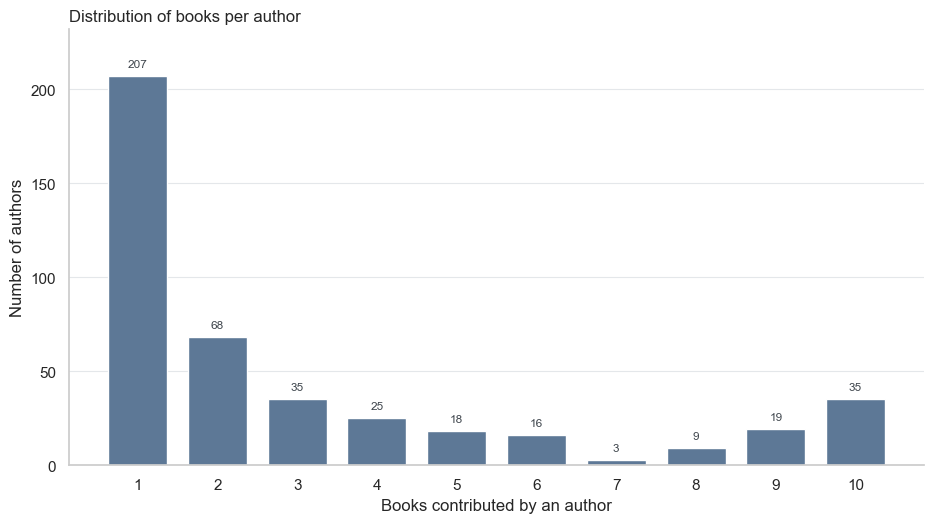

**Brief interpretation.** 207 of 435 authors (47.6%) are represented by one book. Thresholded author comparisons below reduce the influence of single-book author estimates.

In [3]:
AUTHOR_KEY = "author_query"

author_book_data = (
    book_summary_analysis.dropna(subset=[AUTHOR_KEY])
    .drop_duplicates("gutenberg_id")
    .copy()
)
author_overall_summary = (
    author_book_data.groupby(AUTHOR_KEY, as_index=False)
    .agg(
        author_book_count=("gutenberg_id", "nunique"),
        reported_author_book_count=("author_book_count", "max"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
        gender=("author_gender", author_gender_value),
        gender_values=("author_gender", lambda values: values.dropna().nunique()),
    )
    .rename(columns={AUTHOR_KEY: "author"})
)

author_count_mismatches = author_overall_summary.loc[
    author_overall_summary["author_book_count"].ne(
        author_overall_summary["reported_author_book_count"]
    )
]
author_identity_checks = pd.DataFrame(
    {
        "check": [
            "books missing author_query",
            "duplicate Gutenberg IDs in author input",
            "authors with inconsistent gender values",
            "authors whose recomputed count differs from author_book_count",
            "authors represented",
            "maximum books for one author",
        ],
        "count": [
            int(book_summary_analysis[AUTHOR_KEY].isna().sum()),
            int(author_book_data["gutenberg_id"].duplicated().sum()),
            int(author_overall_summary["gender_values"].gt(1).sum()),
            len(author_count_mismatches),
            len(author_overall_summary),
            int(author_overall_summary["author_book_count"].max()),
        ],
    }
)
display(Markdown("**Author aggregation checks**"))
display(author_identity_checks)
if len(author_count_mismatches):
    display(Markdown("**Author-count mismatches**"))
    display(author_count_mismatches)

author_count_distribution = (
    author_overall_summary["author_book_count"]
    .value_counts()
    .reindex(
        range(1, int(author_overall_summary["author_book_count"].max()) + 1),
        fill_value=0,
    )
    .rename_axis("books_per_author")
    .rename("authors")
    .reset_index()
)
display(author_count_distribution)

author_output_dir = ROOT / "final_analysis_publication_outputs"
author_figure_dir = author_output_dir / "figures"
author_table_dir = author_output_dir / "tables"
author_figure_dir.mkdir(parents=True, exist_ok=True)
author_table_dir.mkdir(parents=True, exist_ok=True)
author_count_distribution.to_csv(
    author_table_dir / "author_book_count_distribution.csv",
    index=False,
)
author_overall_summary.drop(columns=["gender_values"]).to_csv(
    author_table_dir / "author_level_interiority_summary.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
bars = ax.bar(
    author_count_distribution["books_per_author"],
    author_count_distribution["authors"],
    color="#5D7896",
    width=0.74,
)
ax.set_xticks(author_count_distribution["books_per_author"])
ax.set_xlabel("Books contributed by an author")
ax.set_ylabel("Number of authors")
ax.set_title("Distribution of books per author", loc="left")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
for bar, authors in zip(bars, author_count_distribution["authors"]):
    if authors > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(author_count_distribution["authors"]) * 0.018,
            f"{authors:,}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color="#3F464D",
        )
ax.set_ylim(0, max(author_count_distribution["authors"]) * 1.12)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(fig, author_figure_dir, "author_book_count_distribution")
plt.show()

one_book_authors = int(
    author_count_distribution.loc[
        author_count_distribution["books_per_author"].eq(1), "authors"
    ].iloc[0]
)
display(
    Markdown(
        f"**Brief interpretation.** {one_book_authors:,} of {len(author_overall_summary):,} authors "
        f"({one_book_authors / len(author_overall_summary):.1%}) are represented by one book. "
        "Thresholded author comparisons below reduce the influence of single-book author estimates."
    )
)

### 2.1 Author-level interiority: thresholded summary

,minimum_books,authors,author_share,books_represented,book_share
0,1,435,100.0%,1348,100.0%
1,3,160,36.8%,1005,74.6%
2,5,100,23.0%,800,59.3%


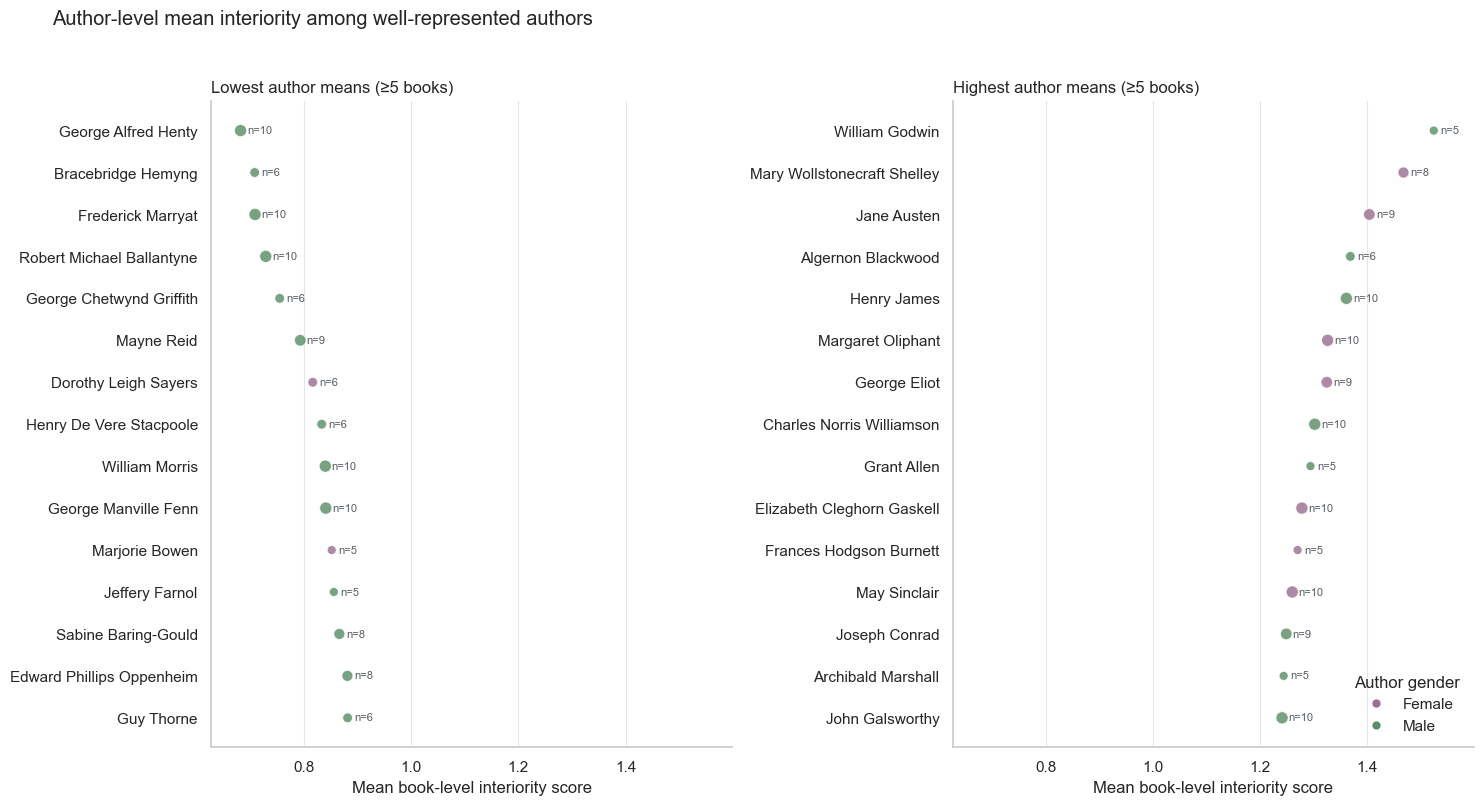

**Lowest ten eligible authors**

,author,gender,author_book_count,average_interiority
0,George Alfred Henty,male,10,0.682
1,Bracebridge Hemyng,male,6,0.708
2,Frederick Marryat,male,10,0.709
3,Robert Michael Ballantyne,male,10,0.729
4,George Chetwynd Griffith,male,6,0.755
5,Mayne Reid,male,9,0.793
6,Dorothy Leigh Sayers,female,6,0.817
7,Henry De Vere Stacpoole,male,6,0.833
8,William Morris,male,10,0.840
9,George Manville Fenn,male,10,0.841


**Highest ten eligible authors**

,author,gender,author_book_count,average_interiority
99,William Godwin,male,5,1.524
98,Mary Wollstonecraft Shelley,female,8,1.468
97,Jane Austen,female,9,1.404
96,Algernon Blackwood,male,6,1.368
95,Henry James,male,10,1.361
94,Margaret Oliphant,female,10,1.326
93,George Eliot,female,9,1.324
92,Charles Norris Williamson,male,10,1.302
91,Grant Allen,male,5,1.294
90,Elizabeth Cleghorn Gaskell,female,10,1.278


In [4]:
threshold_rows = []
for minimum_books in [1, 3, 5]:
    threshold_authors = author_overall_summary.loc[
        author_overall_summary["author_book_count"].ge(minimum_books)
    ]
    threshold_rows.append(
        {
            "minimum_books": minimum_books,
            "authors": len(threshold_authors),
            "author_share": len(threshold_authors) / len(author_overall_summary),
            "books_represented": int(threshold_authors["author_book_count"].sum()),
            "book_share": threshold_authors["author_book_count"].sum()
            / author_overall_summary["author_book_count"].sum(),
        }
    )
author_threshold_coverage = pd.DataFrame(threshold_rows)
display(
    author_threshold_coverage.style.format(
        {"author_share": "{:.1%}", "book_share": "{:.1%}"}
    )
)

AUTHOR_MIN_BOOKS = 5
eligible_authors = (
    author_overall_summary.loc[
        author_overall_summary["author_book_count"].ge(AUTHOR_MIN_BOOKS)
    ]
    .dropna(subset=["average_interiority"])
    .sort_values(["average_interiority", "author"])
    .reset_index(drop=True)
)
eligible_authors.drop(columns=["gender_values"]).to_csv(
    author_table_dir / "author_level_interiority_minimum_5_books.csv",
    index=False,
)

EXTREME_AUTHORS = 15
lowest_authors = eligible_authors.head(EXTREME_AUTHORS).sort_values(
    "average_interiority", ascending=False
)
highest_authors = eligible_authors.tail(EXTREME_AUTHORS).sort_values(
    "average_interiority", ascending=True
)
extreme_frames = [
    (lowest_authors, "Lowest author means"),
    (highest_authors, "Highest author means"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 8.2), sharex=True)
score_min = eligible_authors["average_interiority"].min()
score_max = eligible_authors["average_interiority"].max()
for ax, (frame, title) in zip(axes, extreme_frames):
    y = range(len(frame))
    point_colors = frame["gender"].map(AUTHOR_GENDER_COLORS).fillna(
        AUTHOR_GENDER_COLORS["missing"]
    )
    point_sizes = 42 + (frame["author_book_count"] - AUTHOR_MIN_BOOKS) * 7
    ax.scatter(
        frame["average_interiority"],
        y,
        s=point_sizes,
        c=point_colors,
        alpha=0.82,
        edgecolors="white",
        linewidths=0.6,
        zorder=3,
    )
    ax.set_yticks(list(y), frame["author"])
    ax.set_title(f"{title} (≥{AUTHOR_MIN_BOOKS} books)", loc="left")
    ax.set_xlabel("Mean book-level interiority score")
    ax.set_xlim(score_min - 0.055, score_max + 0.075)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    for position, row in enumerate(frame.itertuples()):
        ax.text(
            row.average_interiority + 0.012,
            position,
            f"n={row.author_book_count}",
            va="center",
            fontsize=8,
            color="#555B61",
        )
    sns.despine(ax=ax)

gender_handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=7,
        label=gender.title(),
    )
    for gender, color in AUTHOR_GENDER_COLORS.items()
    if gender in set(eligible_authors["gender"])
]
axes[1].legend(
    handles=gender_handles,
    title="Author gender",
    frameon=False,
    loc="lower right",
)
fig.suptitle(
    "Author-level mean interiority among well-represented authors",
    x=0.04,
    ha="left",
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, author_figure_dir, "author_interiority_minimum_5_books")
plt.show()

display(Markdown("**Lowest ten eligible authors**"))
display(
    eligible_authors.head(10)[
        ["author", "gender", "author_book_count", "average_interiority"]
    ].style.format({"average_interiority": "{:.3f}"})
)
display(Markdown("**Highest ten eligible authors**"))
display(
    eligible_authors.tail(10).sort_values("average_interiority", ascending=False)[
        ["author", "gender", "author_book_count", "average_interiority"]
    ].style.format({"average_interiority": "{:.3f}"})
)

,author_book_count,authors,mean_author_interiority,sd_author_interiority,minimum_author_interiority,maximum_author_interiority
0,1,207,1.091,0.218,0.240,1.620
1,2,68,1.114,0.172,0.665,1.430
2,3,35,1.075,0.200,0.723,1.483
3,4,25,1.113,0.158,0.807,1.435
4,5,18,1.132,0.170,0.852,1.524
5,6,16,0.985,0.195,0.708,1.368
6,7,3,1.058,0.135,0.903,1.150
7,8,9,1.069,0.203,0.866,1.468
8,9,19,1.081,0.149,0.793,1.404
9,10,35,1.057,0.176,0.682,1.361


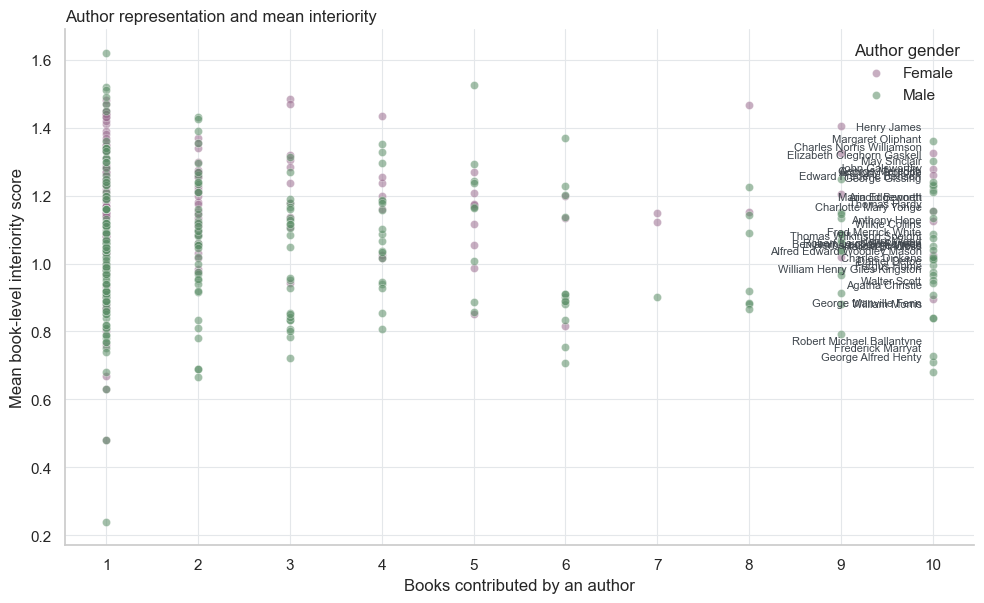

**Brief interpretation.** The ≥5-book subset contains 100 authors representing 800 books (59.3% of the corpus). Across all authors, the descriptive correlation between book count and author mean interiority is -0.06; the scatter is exploratory and does not imply that representation causes differences in interiority.

In [5]:
author_count_interiority_summary = (
    author_overall_summary.dropna(subset=["average_interiority"])
    .groupby("author_book_count", as_index=False)
    .agg(
        authors=("author", "size"),
        mean_author_interiority=("average_interiority", "mean"),
        sd_author_interiority=("average_interiority", "std"),
        minimum_author_interiority=("average_interiority", "min"),
        maximum_author_interiority=("average_interiority", "max"),
    )
)
display(
    author_count_interiority_summary.style.format(
        {
            "mean_author_interiority": "{:.3f}",
            "sd_author_interiority": "{:.3f}",
            "minimum_author_interiority": "{:.3f}",
            "maximum_author_interiority": "{:.3f}",
        }
    )
)
author_count_interiority_summary.to_csv(
    author_table_dir / "author_book_count_interiority_summary.csv",
    index=False,
)

author_scatter_data = author_overall_summary.dropna(
    subset=["average_interiority"]
).copy()
fig, ax = plt.subplots(figsize=(10, 6.2))
for gender in ["female", "male", "missing"]:
    gender_data = author_scatter_data.loc[
        author_scatter_data["gender"].eq(gender)
    ]
    if gender_data.empty:
        continue
    ax.scatter(
        gender_data["author_book_count"],
        gender_data["average_interiority"],
        s=34,
        alpha=0.56,
        color=AUTHOR_GENDER_COLORS[gender],
        edgecolors="white",
        linewidths=0.35,
        label=gender.title(),
    )

max_count = int(author_scatter_data["author_book_count"].max())
ax.set_xticks(range(1, max_count + 1))
ax.set_xlabel("Books contributed by an author")
ax.set_ylabel("Mean book-level interiority score")
ax.set_title("Author representation and mean interiority", loc="left")
ax.grid(color="#E4E7EA", linewidth=0.8)
ax.legend(title="Author gender", frameon=False)

for row in author_scatter_data.loc[
    author_scatter_data["author_book_count"].eq(max_count)
].itertuples():
    ax.annotate(
        row.author,
        (row.author_book_count, row.average_interiority),
        xytext=(-8, 8),
        textcoords="offset points",
        ha="right",
        fontsize=8,
        color="#3F464D",
    )
sns.despine(ax=ax)
plt.tight_layout()
save_figure(fig, author_figure_dir, "author_book_count_vs_mean_interiority")
plt.show()

descriptive_correlation = author_scatter_data[
    ["author_book_count", "average_interiority"]
].corr().iloc[0, 1]
eligible_row = author_threshold_coverage.loc[
    author_threshold_coverage["minimum_books"].eq(AUTHOR_MIN_BOOKS)
].iloc[0]
display(
    Markdown(
        f"**Brief interpretation.** The ≥{AUTHOR_MIN_BOOKS}-book subset contains "
        f"{int(eligible_row['authors']):,} authors representing {int(eligible_row['books_represented']):,} books "
        f"({eligible_row['book_share']:.1%} of the corpus). Across all authors, the descriptive correlation "
        f"between book count and author mean interiority is {descriptive_correlation:.2f}; the scatter is "
        "exploratory and does not imply that representation causes differences in interiority."
    )
)

## 3. Author-gender summary

In [6]:
gender_overall_summary = (
    book_summary_analysis.assign(
        gender_summary=book_summary_analysis["author_gender"].fillna("missing")
    )
    .groupby("gender_summary", as_index=False)
    .agg(
        books=("gutenberg_id", "nunique"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
    )
)
gender_overall_summary["book_share"] = (
    gender_overall_summary["books"]
    / gender_overall_summary["books"].sum()
)

display(
    gender_overall_summary.sort_values(
        "books", ascending=False
    ).style.format(
        {
            "average_interiority": "{:.3f}",
            "book_share": "{:.1%}",
        }
    )
)

,gender_summary,books,books_with_score,average_interiority,book_share
1,male,944,944,1.038,70.0%
0,female,397,397,1.171,29.5%
2,unknown,7,7,1.024,0.5%


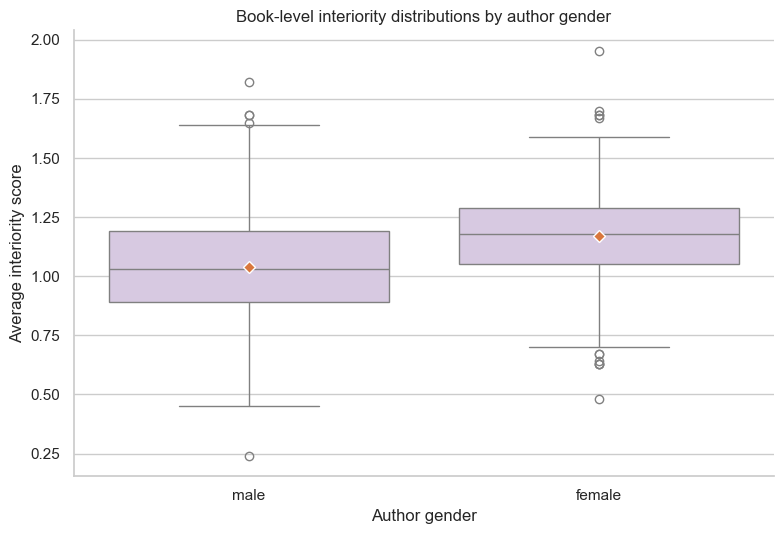

In [7]:
gender_boxplot_data = (
    book_summary_analysis.assign(
        gender_plot=book_summary_analysis["author_gender"].fillna("missing")
    )
    .dropna(subset=["avg_interiority_score"])
)
gender_box_order = [
    value
    for value in ["male", "female", "missing"]
    if value in set(gender_boxplot_data["gender_plot"])
]

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(
    data=gender_boxplot_data,
    x="gender_plot",
    y="avg_interiority_score",
    order=gender_box_order,
    color="#D8C5E5",
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#D9773D",
        "markeredgecolor": "white",
        "markersize": 6,
    },
    ax=ax,
)
ax.set_title("Book-level interiority distributions by author gender")
ax.set_xlabel("Author gender")
ax.set_ylabel("Average interiority score")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 3.1 Author-gender trend over publication year


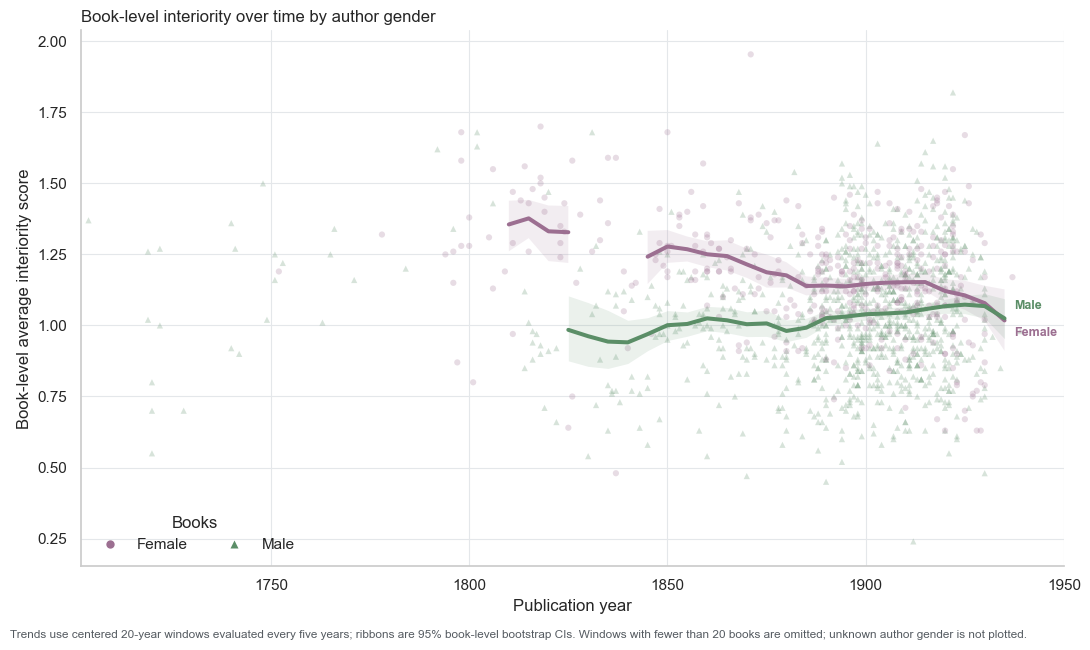

,books_plotted
author_gender,
male,944
female,397


**Brief interpretation.** The points show book-level variation; the rolling lines and ribbons summarize local book-level means. 7 books with unknown author gender are omitted. The figure is exploratory and does not adjust for changing corpus composition.

In [8]:
gender_time_data = (
    book_summary_analysis.assign(
        gender_plot=book_summary_analysis["author_gender"],
        publication_year_plot=pd.to_numeric(
            book_summary_analysis["publication_year"], errors="coerce"
        ),
        interiority_plot=pd.to_numeric(
            book_summary_analysis["avg_interiority_score"], errors="coerce"
        ),
    )
    .loc[lambda frame: frame["gender_plot"].isin(["female", "male"])]
    .dropna(subset=["publication_year_plot", "interiority_plot"])
    .copy()
)

ROLLING_WINDOW_YEARS = 20
ROLLING_EVALUATION_STEP = 5
ROLLING_MINIMUM_BOOKS = 20
gender_publication_trends = rolling_book_bootstrap(
    gender_time_data,
    group_column="gender_plot",
    groups=["female", "male"],
    year_column="publication_year_plot",
    score_column="interiority_plot",
    window_years=ROLLING_WINDOW_YEARS,
    evaluation_step=ROLLING_EVALUATION_STEP,
    minimum_books=ROLLING_MINIMUM_BOOKS,
    seed_key="gender_publication_trend",
)
gender_publication_trends.to_csv(
    author_table_dir / "gender_publication_year_rolling_trends.csv",
    index=False,
)

GENDER_MARKERS = {
    "female": "o",
    "male": "^",
}
fig, ax = plt.subplots(figsize=(11, 6.4))
for gender in ["male", "female"]:
    group_data = gender_time_data.loc[
        gender_time_data["gender_plot"].eq(gender)
    ]
    if group_data.empty:
        continue
    ax.scatter(
        group_data["publication_year_plot"],
        group_data["interiority_plot"],
        s=20,
        alpha=0.24,
        marker=GENDER_MARKERS[gender],
        color=AUTHOR_GENDER_COLORS[gender],
        edgecolors="none",
        zorder=2,
    )

for gender in ["female", "male"]:
    trend = gender_publication_trends.loc[
        gender_publication_trends["gender_plot"].eq(gender)
    ].sort_values("evaluation_year")
    x = trend["evaluation_year"].to_numpy(float)
    estimate = trend["estimate"].to_numpy(float)
    ci_low = trend["ci_low"].to_numpy(float)
    ci_high = trend["ci_high"].to_numpy(float)
    valid_ci = np.isfinite(ci_low) & np.isfinite(ci_high)
    ax.fill_between(
        x,
        ci_low,
        ci_high,
        where=valid_ci,
        color=AUTHOR_GENDER_COLORS[gender],
        alpha=0.12,
        linewidth=0,
        zorder=3,
    )
    ax.plot(
        x,
        estimate,
        color=AUTHOR_GENDER_COLORS[gender],
        linewidth=2.9,
        zorder=4,
    )
    valid_trend = trend.dropna(subset=["estimate"])
    if len(valid_trend):
        last = valid_trend.iloc[-1]
        author_label_y_offset = {
            "female": -9,
            "male": 9,
        }
        ax.annotate(
            gender.title(),
            (last["evaluation_year"], last["estimate"]),
            xytext=(7, author_label_y_offset[gender]),
            textcoords="offset points",
            color=AUTHOR_GENDER_COLORS[gender],
            fontsize=9,
            fontweight="bold",
            va="center",
        )

point_handles = [
    plt.Line2D(
        [0],
        [0],
        marker=GENDER_MARKERS[gender],
        linestyle="none",
        markerfacecolor=AUTHOR_GENDER_COLORS[gender],
        markeredgecolor="none",
        markersize=6,
        label=gender.title(),
    )
    for gender in ["female", "male"]
]
ax.legend(
    handles=point_handles,
    title="Books",
    frameon=False,
    loc="lower left",
    ncol=2,
)
ax.set_xlabel("Publication year")
ax.set_ylabel("Book-level average interiority score")
ax.set_title("Book-level interiority over time by author gender", loc="left")
ax.set_xlim(
    gender_time_data["publication_year_plot"].min() - 2,
    gender_time_data["publication_year_plot"].max() + 11,
)
ax.grid(color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
fig.text(
    0.01,
    -0.01,
    "Trends use centered 20-year windows evaluated every five years; ribbons are 95% book-level bootstrap CIs. "
    "Windows with fewer than 20 books are omitted; unknown author gender is not plotted.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(fig, author_figure_dir, "gender_publication_year_trends")
plt.show()

gender_plot_counts = (
    gender_time_data["gender_plot"]
    .value_counts()
    .rename_axis("author_gender")
    .rename("books_plotted")
    .to_frame()
)
display(gender_plot_counts)
unknown_author_gender_books = int(
    book_summary_analysis["author_gender"].eq("unknown").sum()
)
display(
    Markdown(
        f"**Brief interpretation.** The points show book-level variation; the rolling lines and ribbons "
        f"summarize local book-level means. {unknown_author_gender_books} books with unknown author gender "
        "are omitted. The figure is exploratory and does not adjust for changing corpus composition."
    )
)


### 3.2 Author gender by historical period


,author_gender,time_period,historical_period,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,female,<1840,Pre-1840,48,1.294,1.219,1.363,standard_n_ge_20,True,5000,20260731
1,female,1840-1899,1840–1899,168,1.182,1.159,1.207,standard_n_ge_20,True,5000,20260731
2,female,1900+,1900+,181,1.128,1.099,1.155,standard_n_ge_20,True,5000,20260731
3,male,<1840,Pre-1840,61,1.055,0.986,1.128,standard_n_ge_20,True,5000,20260731
4,male,1840-1899,1840–1899,384,1.018,0.997,1.040,standard_n_ge_20,True,5000,20260731
5,male,1900+,1900+,499,1.052,1.033,1.070,standard_n_ge_20,True,5000,20260731


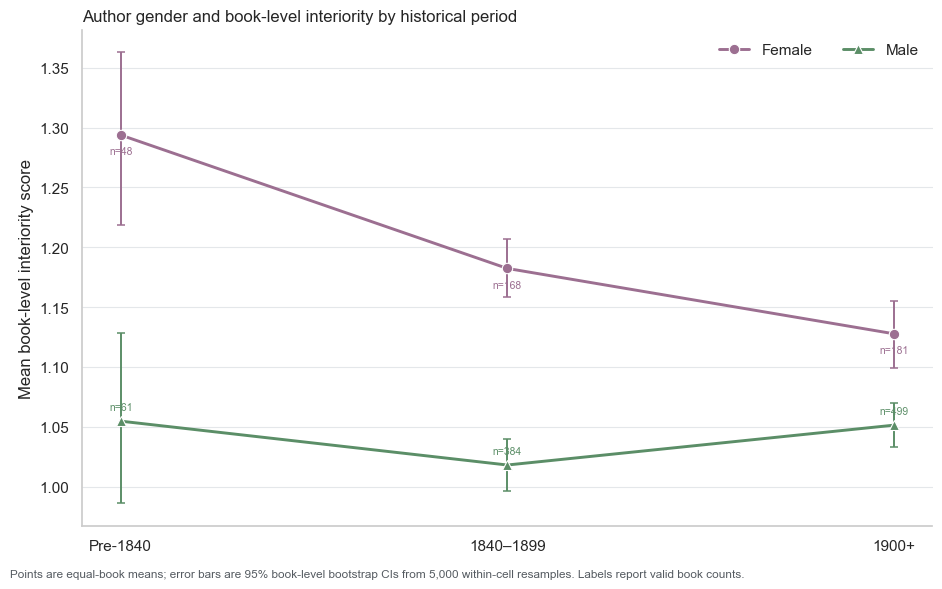

**Brief interpretation.** The period means summarize female- and male-authored books with equal weight per book. They are descriptive and reflect the books represented in each period.

In [9]:
PERIOD_DISPLAY_LABELS = {
    "<1840": "Pre-1840",
    "1840-1899": "1840–1899",
    "1900+": "1900+",
}


def summarize_gender_periods(
    data,
    *,
    group_column,
    groups,
    seed_key,
):
    """Book-level means and fixed-seed bootstrap CIs by group × period."""
    working = (
        data[
            [
                "gutenberg_id",
                group_column,
                "time_period",
                "avg_interiority_score",
            ]
        ]
        .drop_duplicates("gutenberg_id")
        .copy()
    )
    rows = []
    for group in groups:
        for period in TIME_PERIOD_ORDER:
            values = working.loc[
                working[group_column].eq(group)
                & working["time_period"].eq(period),
                "avg_interiority_score",
            ]
            summary = bootstrap_mean_summary(
                values,
                seed_key,
                group,
                period,
            )
            rows.append(
                {
                    group_column: group,
                    "time_period": period,
                    "historical_period": PERIOD_DISPLAY_LABELS[period],
                    **summary,
                }
            )
    return pd.DataFrame(rows)


def plot_gender_periods(
    summary,
    *,
    group_column,
    groups,
    colors,
    markers,
    labels,
    title,
    figure_stem,
):
    """Parallel line-and-point period figure with bootstrap error bars."""
    fig, ax = plt.subplots(figsize=(9.5, 5.8))
    x_positions = np.arange(len(TIME_PERIOD_ORDER))
    count_offsets = (
        [(0, -14), (0, 8)]
        if len(groups) == 2
        else [(-15, -14), (0, 8), (15, 8)]
    )

    for group_index, group in enumerate(groups):
        panel = (
            summary.loc[summary[group_column].eq(group)]
            .set_index("time_period")
            .reindex(TIME_PERIOD_ORDER)
        )
        estimates = panel["estimate"].to_numpy(float)
        ci_low = panel["ci_low"].to_numpy(float)
        ci_high = panel["ci_high"].to_numpy(float)
        color = colors[group]
        marker = markers[group]

        ax.plot(
            x_positions,
            estimates,
            color=color,
            marker=marker,
            markersize=7.5,
            markerfacecolor=color,
            markeredgecolor="white",
            markeredgewidth=0.8,
            linewidth=2.1,
            label=labels[group],
            zorder=3,
        )
        valid_ci = (
            np.isfinite(estimates)
            & np.isfinite(ci_low)
            & np.isfinite(ci_high)
        )
        ax.errorbar(
            x_positions[valid_ci],
            estimates[valid_ci],
            yerr=np.vstack(
                [
                    estimates[valid_ci] - ci_low[valid_ci],
                    ci_high[valid_ci] - estimates[valid_ci],
                ]
            ),
            fmt="none",
            ecolor=color,
            elinewidth=1.4,
            capsize=3,
            capthick=1.1,
            zorder=2,
        )
        for x_position, estimate, n_books in zip(
            x_positions,
            estimates,
            panel["n_books"].to_numpy(int),
        ):
            if np.isfinite(estimate):
                ax.annotate(
                    f"n={n_books}",
                    (x_position, estimate),
                    xytext=count_offsets[group_index],
                    textcoords="offset points",
                    ha="center",
                    fontsize=7.5,
                    color=color,
                )

    ax.set_xticks(
        x_positions,
        [PERIOD_DISPLAY_LABELS[period] for period in TIME_PERIOD_ORDER],
    )
    ax.set_xlabel("")
    ax.set_ylabel("Mean book-level interiority score")
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, ncol=len(groups), loc="best")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
    sns.despine(ax=ax)
    fig.text(
        0.01,
        -0.01,
        "Points are equal-book means; error bars are 95% book-level bootstrap CIs "
        "from 5,000 within-cell resamples. Labels report valid book counts.",
        fontsize=8.5,
        color="#555B61",
    )
    plt.tight_layout()
    save_figure(fig, author_figure_dir, figure_stem)
    return fig


AUTHOR_GENDER_ORDER = ["female", "male"]
AUTHOR_GENDER_LABELS = {
    "female": "Female",
    "male": "Male",
}
author_gender_period_summary = summarize_gender_periods(
    book_summary_analysis.loc[
        book_summary_analysis["author_gender"].isin(AUTHOR_GENDER_ORDER)
    ],
    group_column="author_gender",
    groups=AUTHOR_GENDER_ORDER,
    seed_key="author_gender_period",
)
author_gender_period_summary.to_csv(
    author_table_dir / "author_gender_period_bootstrap.csv",
    index=False,
)
display(
    author_gender_period_summary.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig = plot_gender_periods(
    author_gender_period_summary,
    group_column="author_gender",
    groups=AUTHOR_GENDER_ORDER,
    colors=AUTHOR_GENDER_COLORS,
    markers=GENDER_MARKERS,
    labels=AUTHOR_GENDER_LABELS,
    title="Author gender and book-level interiority by historical period",
    figure_stem="author_gender_period_estimates",
)
plt.show()
display(
    Markdown(
        "**Brief interpretation.** The period means summarize female- and male-authored books "
        "with equal weight per book. They are descriptive and reflect the books represented in each period."
    )
)


### 3.3 Author gender × broad-group analysis


In [10]:
BROAD_GROUP_ANALYSIS_CROSS_ORDER = [
    "all_domestic",
    "major_genre_non_domestic",
    "other_non_domestic_non_major_genre",
    "missing",
]

author_gender_broad_group_data = (
    book_summary_analysis.loc[
        book_summary_analysis["author_gender"].isin(AUTHOR_GENDER_ORDER),
        ["gutenberg_id", "author_gender", "broad_group_analysis"],
    ]
    .drop_duplicates("gutenberg_id")
    .assign(
        broad_group_analysis=lambda frame: frame[
            "broad_group_analysis"
        ].fillna("missing")
    )
)
author_gender_broad_group_counts = (
    pd.crosstab(
        author_gender_broad_group_data["author_gender"],
        author_gender_broad_group_data["broad_group_analysis"],
    )
    .reindex(index=AUTHOR_GENDER_ORDER, fill_value=0)
    .reindex(
        columns=[
            group
            for group in BROAD_GROUP_ANALYSIS_CROSS_ORDER
            if group in set(
                author_gender_broad_group_data["broad_group_analysis"]
            )
        ],
        fill_value=0,
    )
)
author_gender_broad_group_counts["Total"] = (
    author_gender_broad_group_counts.sum(axis=1)
)
author_gender_broad_group_counts.to_csv(
    author_table_dir / "author_gender_by_broad_group_analysis_counts.csv"
)
display(author_gender_broad_group_counts)
display(
    Markdown(
        "**Brief note.** Cells are book counts. The seven books with unknown author gender "
        "are excluded; each remaining book appears in exactly one broad-group-analysis column."
    )
)


broad_group_analysis,all_domestic,major_genre_non_domestic,other_non_domestic_non_major_genre,Total
author_gender,,,,
female,208,125,64,397
male,255,554,135,944


**Brief note.** Cells are book counts. The seven books with unknown author gender are excluded; each remaining book appears in exactly one broad-group-analysis column.

## 4. Protagonist-gender summary

All analyses in this section are restricted to books with `protagonist_analysis_status == "included"`.


In [11]:
protagonist_included_books = (
    book_summary_analysis.loc[
        book_summary_analysis["protagonist_analysis_status"].eq("included")
    ]
    .copy()
)

protagonist_included_books["protagonist_gender"].value_counts()


protagonist_gender
M        551
F        346
mixed    119
Name: count, dtype: int64

In [12]:
protagonist_included_books['protagonist_structure'].value_counts()

protagonist_structure
single_dominant         740
mixed_gender            119
multiple_same_gender     86
Name: count, dtype: int64

In [13]:
protagonist_included_books['protagonist_analysis_status'].value_counts()

protagonist_analysis_status
included    1016
Name: count, dtype: int64

In [14]:
protagonist_included_books[protagonist_included_books['protagonist_analysis_status']=='included']['protagonist_gender'].value_counts()

protagonist_gender
M        551
F        346
mixed    119
Name: count, dtype: int64

### 4.1 Protagonist gender over publication year


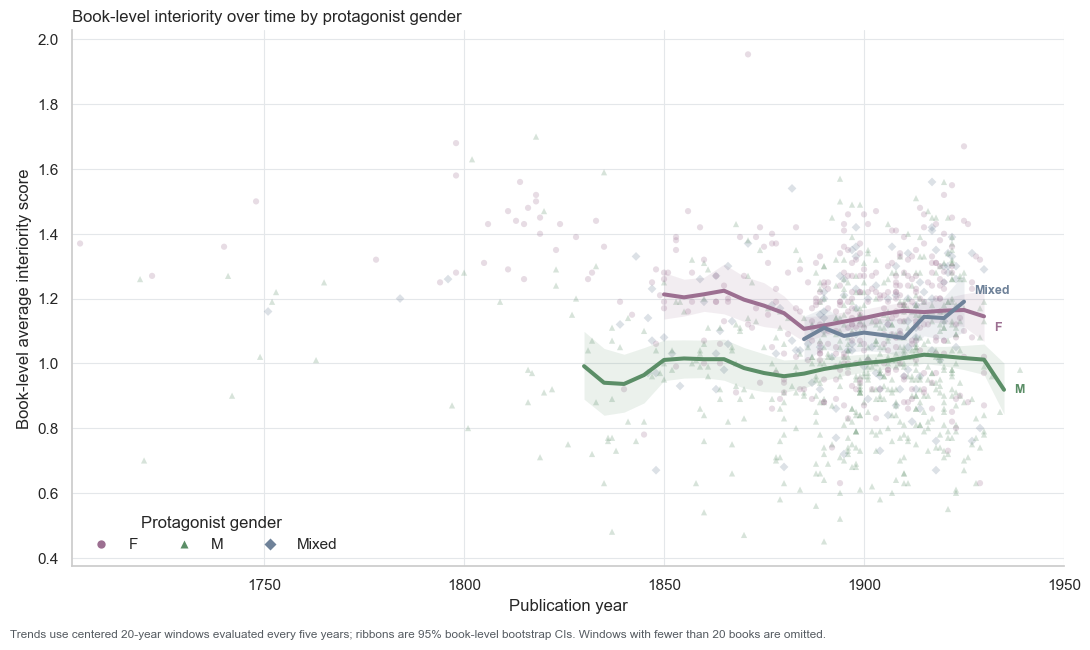

,books_plotted
protagonist_gender,
F,346
M,551
mixed,119


**Brief interpretation.** The scatter and rolling summaries retain F, M, and mixed as separate book-level groups. Within the included-status subset, 0 books fall outside these three protagonist-gender groups.

In [15]:
PROTAGONIST_GENDER_ORDER = ["F", "M", "mixed"]
PROTAGONIST_GENDER_LABELS = {
    "F": "F",
    "M": "M",
    "mixed": "Mixed",
}
PROTAGONIST_GENDER_COLORS = {
    "F": AUTHOR_GENDER_COLORS["female"],
    "M": AUTHOR_GENDER_COLORS["male"],
    "mixed": "#6F8299",
}
PROTAGONIST_GENDER_MARKERS = {
    "F": "o",
    "M": "^",
    "mixed": "D",
}

protagonist_time_data = (
    protagonist_included_books.loc[
        protagonist_included_books["protagonist_gender"].isin(
            PROTAGONIST_GENDER_ORDER
        )
    ]
    .assign(
        publication_year_plot=lambda frame: pd.to_numeric(
            frame["publication_year"], errors="coerce"
        ),
        interiority_plot=lambda frame: pd.to_numeric(
            frame["avg_interiority_score"], errors="coerce"
        ),
    )
    .dropna(subset=["publication_year_plot", "interiority_plot"])
    .copy()
)

protagonist_gender_publication_trends = rolling_book_bootstrap(
    protagonist_time_data,
    group_column="protagonist_gender",
    groups=PROTAGONIST_GENDER_ORDER,
    year_column="publication_year_plot",
    score_column="interiority_plot",
    window_years=ROLLING_WINDOW_YEARS,
    evaluation_step=ROLLING_EVALUATION_STEP,
    minimum_books=ROLLING_MINIMUM_BOOKS,
    seed_key="protagonist_gender_publication_trend",
)
protagonist_gender_publication_trends.to_csv(
    author_table_dir / "protagonist_gender_publication_year_rolling_trends.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(11, 6.4))
for group in ["mixed", "M", "F"]:
    group_data = protagonist_time_data.loc[
        protagonist_time_data["protagonist_gender"].eq(group)
    ]
    ax.scatter(
        group_data["publication_year_plot"],
        group_data["interiority_plot"],
        s=20,
        alpha=0.24,
        marker=PROTAGONIST_GENDER_MARKERS[group],
        color=PROTAGONIST_GENDER_COLORS[group],
        edgecolors="none",
        zorder=2,
    )

for group in PROTAGONIST_GENDER_ORDER:
    trend = protagonist_gender_publication_trends.loc[
        protagonist_gender_publication_trends["protagonist_gender"].eq(group)
    ].sort_values("evaluation_year")
    x = trend["evaluation_year"].to_numpy(float)
    estimate = trend["estimate"].to_numpy(float)
    ci_low = trend["ci_low"].to_numpy(float)
    ci_high = trend["ci_high"].to_numpy(float)
    valid_ci = np.isfinite(ci_low) & np.isfinite(ci_high)
    color = PROTAGONIST_GENDER_COLORS[group]
    ax.fill_between(
        x,
        ci_low,
        ci_high,
        where=valid_ci,
        color=color,
        alpha=0.12,
        linewidth=0,
        zorder=3,
    )
    ax.plot(
        x,
        estimate,
        color=color,
        linewidth=2.9,
        zorder=4,
    )
    valid_trend = trend.dropna(subset=["estimate"])
    if len(valid_trend):
        last = valid_trend.iloc[-1]
        protagonist_label_y_offset = {
            "F": -8,
            "M": 0,
            "mixed": 8,
        }
        ax.annotate(
            PROTAGONIST_GENDER_LABELS[group],
            (last["evaluation_year"], last["estimate"]),
            xytext=(7, protagonist_label_y_offset[group]),
            textcoords="offset points",
            color=color,
            fontsize=9,
            fontweight="bold",
            va="center",
        )

point_handles = [
    plt.Line2D(
        [0],
        [0],
        marker=PROTAGONIST_GENDER_MARKERS[group],
        linestyle="none",
        markerfacecolor=PROTAGONIST_GENDER_COLORS[group],
        markeredgecolor="none",
        markersize=6,
        label=PROTAGONIST_GENDER_LABELS[group],
    )
    for group in PROTAGONIST_GENDER_ORDER
]
ax.legend(
    handles=point_handles,
    title="Protagonist gender",
    frameon=False,
    loc="lower left",
    ncol=3,
)
ax.set_xlabel("Publication year")
ax.set_ylabel("Book-level average interiority score")
ax.set_title("Book-level interiority over time by protagonist gender", loc="left")
ax.set_xlim(
    protagonist_time_data["publication_year_plot"].min() - 2,
    protagonist_time_data["publication_year_plot"].max() + 11,
)
ax.grid(color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
fig.text(
    0.01,
    -0.01,
    "Trends use centered 20-year windows evaluated every five years; ribbons are 95% book-level bootstrap CIs. "
    "Windows with fewer than 20 books are omitted.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(fig, author_figure_dir, "protagonist_gender_publication_year_trends")
plt.show()

protagonist_gender_plot_counts = (
    protagonist_time_data["protagonist_gender"]
    .value_counts()
    .reindex(PROTAGONIST_GENDER_ORDER)
    .rename_axis("protagonist_gender")
    .rename("books_plotted")
    .to_frame()
)
display(protagonist_gender_plot_counts)
excluded_protagonist_gender_books = int(
    (~protagonist_included_books["protagonist_gender"].isin(PROTAGONIST_GENDER_ORDER)).sum()
)
display(
    Markdown(
        f"**Brief interpretation.** The scatter and rolling summaries retain F, M, and mixed as separate "
        f"book-level groups. Within the included-status subset, {excluded_protagonist_gender_books} books "
        "fall outside these three protagonist-gender groups."
    )
)


### 4.2 Protagonist gender by historical period


,protagonist_gender,time_period,historical_period,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,F,<1840,Pre-1840,30,1.395,1.356,1.436,standard_n_ge_20,True,5000,20260731
1,F,1840-1899,1840–1899,154,1.148,1.120,1.176,standard_n_ge_20,True,5000,20260731
2,F,1900+,1900+,162,1.158,1.131,1.186,standard_n_ge_20,True,5000,20260731
3,M,<1840,Pre-1840,43,1.038,0.955,1.121,standard_n_ge_20,True,5000,20260731
4,M,1840-1899,1840–1899,219,0.986,0.958,1.014,standard_n_ge_20,True,5000,20260731
5,M,1900+,1900+,289,1.015,0.992,1.037,standard_n_ge_20,True,5000,20260731
6,mixed,<1840,Pre-1840,4,1.185,1.140,1.235,mean_only_n_lt_10,False,5000,20260731
7,mixed,1840-1899,1840–1899,57,1.106,1.058,1.151,standard_n_ge_20,True,5000,20260731
8,mixed,1900+,1900+,58,1.112,1.061,1.162,standard_n_ge_20,True,5000,20260731


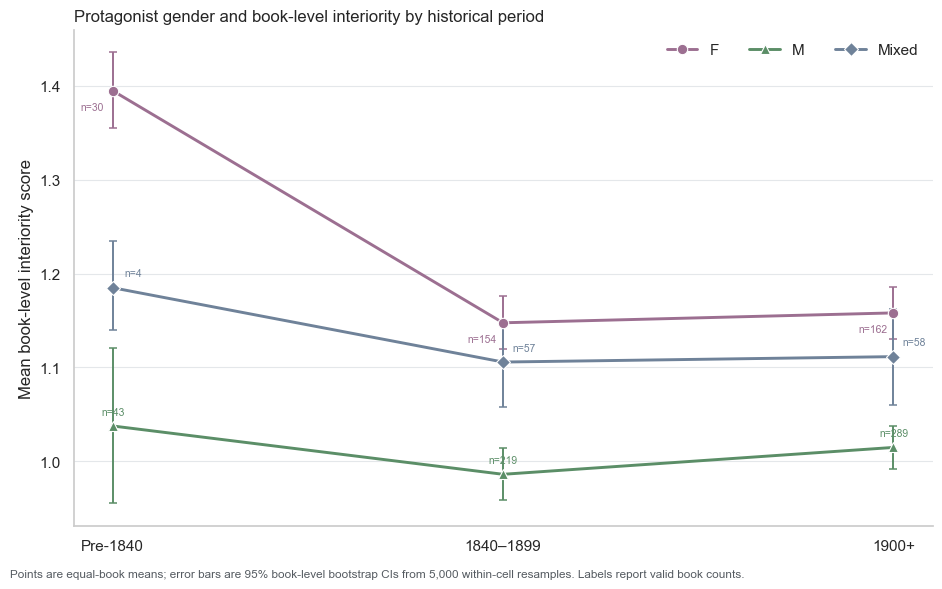

**Brief interpretation.** The three period series use the same equal-book bootstrap format as the author-gender figure. The mixed Pre-1840 cell is especially small and should be read descriptively.

In [16]:
protagonist_gender_period_summary = summarize_gender_periods(
    protagonist_included_books.loc[
        protagonist_included_books["protagonist_gender"].isin(
            PROTAGONIST_GENDER_ORDER
        )
    ],
    group_column="protagonist_gender",
    groups=PROTAGONIST_GENDER_ORDER,
    seed_key="protagonist_gender_period",
)
protagonist_gender_period_summary.to_csv(
    author_table_dir / "protagonist_gender_period_bootstrap.csv",
    index=False,
)
display(
    protagonist_gender_period_summary.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig = plot_gender_periods(
    protagonist_gender_period_summary,
    group_column="protagonist_gender",
    groups=PROTAGONIST_GENDER_ORDER,
    colors=PROTAGONIST_GENDER_COLORS,
    markers=PROTAGONIST_GENDER_MARKERS,
    labels=PROTAGONIST_GENDER_LABELS,
    title="Protagonist gender and book-level interiority by historical period",
    figure_stem="protagonist_gender_period_estimates",
)
plt.show()
display(
    Markdown(
        "**Brief interpretation.** The three period series use the same equal-book bootstrap format "
        "as the author-gender figure. The mixed Pre-1840 cell is especially small and should be read descriptively."
    )
)


### 4.3 Overall protagonist-gender summary


,protagonist_gender,group_label,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,F,F,346,1.174,1.154,1.193,standard_n_ge_20,True,5000,20260731
1,M,M,551,1.005,0.988,1.023,standard_n_ge_20,True,5000,20260731
2,mixed,Mixed,119,1.111,1.077,1.144,standard_n_ge_20,True,5000,20260731


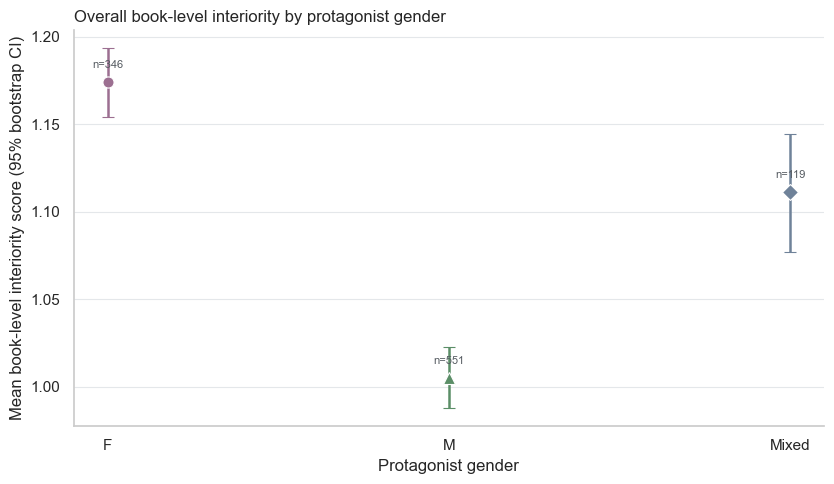

**Brief interpretation.** The points compare equal-book means for F, M, and mixed; whiskers show within-group book-level bootstrap uncertainty.

In [17]:
protagonist_gender_overall_rows = []
for group in PROTAGONIST_GENDER_ORDER:
    values = protagonist_included_books.loc[
        protagonist_included_books["protagonist_gender"].eq(group),
        "avg_interiority_score",
    ]
    summary = bootstrap_mean_summary(
        values,
        "protagonist_gender_overall",
        group,
    )
    protagonist_gender_overall_rows.append(
        {
            "protagonist_gender": group,
            "group_label": PROTAGONIST_GENDER_LABELS[group],
            **summary,
        }
    )

protagonist_gender_overall_summary = pd.DataFrame(
    protagonist_gender_overall_rows
)
protagonist_gender_overall_summary.to_csv(
    author_table_dir / "protagonist_gender_overall_bootstrap.csv",
    index=False,
)
display(
    protagonist_gender_overall_summary.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(8.5, 5.0))
x_positions = np.arange(len(PROTAGONIST_GENDER_ORDER))
panel = (
    protagonist_gender_overall_summary
    .set_index("protagonist_gender")
    .reindex(PROTAGONIST_GENDER_ORDER)
)
for x_position, (group, row) in zip(x_positions, panel.iterrows()):
    color = PROTAGONIST_GENDER_COLORS[group]
    ax.errorbar(
        x_position,
        row["estimate"],
        yerr=[
            [row["estimate"] - row["ci_low"]],
            [row["ci_high"] - row["estimate"]],
        ],
        fmt=PROTAGONIST_GENDER_MARKERS[group],
        markersize=8,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=0.8,
        color=color,
        ecolor=color,
        elinewidth=1.8,
        capsize=4,
        capthick=1.2,
        linestyle="none",
        zorder=3,
    )
    ax.annotate(
        f"n={int(row['n_books'])}",
        (x_position, row["estimate"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#555B61",
    )

ax.set_xticks(
    x_positions,
    [PROTAGONIST_GENDER_LABELS[group] for group in PROTAGONIST_GENDER_ORDER],
)
ax.set_xlabel("Protagonist gender")
ax.set_ylabel("Mean book-level interiority score (95% bootstrap CI)")
ax.set_title("Overall book-level interiority by protagonist gender", loc="left")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(fig, author_figure_dir, "protagonist_gender_overall_summary")
plt.show()
display(
    Markdown(
        "**Brief interpretation.** The points compare equal-book means for F, M, and mixed; "
        "whiskers show within-group book-level bootstrap uncertainty."
    )
)


### 4.4 Protagonist gender × broad-group analysis


In [18]:
protagonist_gender_broad_group_data = (
    protagonist_included_books.loc[
        protagonist_included_books["protagonist_gender"].isin(
            PROTAGONIST_GENDER_ORDER
        ),
        ["gutenberg_id", "protagonist_gender", "broad_group_analysis"],
    ]
    .drop_duplicates("gutenberg_id")
    .assign(
        broad_group_analysis=lambda frame: frame[
            "broad_group_analysis"
        ].fillna("missing")
    )
)
protagonist_gender_broad_group_counts = (
    pd.crosstab(
        protagonist_gender_broad_group_data["protagonist_gender"],
        protagonist_gender_broad_group_data["broad_group_analysis"],
    )
    .reindex(index=PROTAGONIST_GENDER_ORDER, fill_value=0)
    .reindex(
        columns=[
            group
            for group in BROAD_GROUP_ANALYSIS_CROSS_ORDER
            if group in set(
                protagonist_gender_broad_group_data["broad_group_analysis"]
            )
        ],
        fill_value=0,
    )
)
protagonist_gender_broad_group_counts["Total"] = (
    protagonist_gender_broad_group_counts.sum(axis=1)
)
protagonist_gender_broad_group_counts.to_csv(
    author_table_dir
    / "protagonist_gender_by_broad_group_analysis_counts.csv"
)
display(protagonist_gender_broad_group_counts)
display(
    Markdown(
        "**Brief note.** Cells are book counts for F, M, and mixed within the "
        "included-status subset."
    )
)


broad_group_analysis,all_domestic,major_genre_non_domestic,other_non_domestic_non_major_genre,Total
protagonist_gender,,,,
F,206,82,58,346
M,134,342,75,551
mixed,53,43,23,119


**Brief note.** Cells are book counts for F, M, and mixed within the included-status subset.

#### Protagonist gender over time within domestic and non-domestic books

These comparisons retain included-status books with F or M protagonist gender. Non-domestic combines major-genre and other non-domestic books.


**Domestic books**

,protagonist_gender,time_period,historical_period,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,F,<1840,Pre-1840,12,1.428,1.384,1.472,limited_n_10_19,True,5000,20260731
1,F,1840-1899,1840–1899,85,1.192,1.161,1.221,standard_n_ge_20,True,5000,20260731
2,F,1900+,1900+,109,1.214,1.184,1.244,standard_n_ge_20,True,5000,20260731
3,M,<1840,Pre-1840,2,0.855,0.730,0.980,mean_only_n_lt_10,False,5000,20260731
4,M,1840-1899,1840–1899,53,1.112,1.069,1.156,standard_n_ge_20,True,5000,20260731
5,M,1900+,1900+,79,1.160,1.122,1.198,standard_n_ge_20,True,5000,20260731


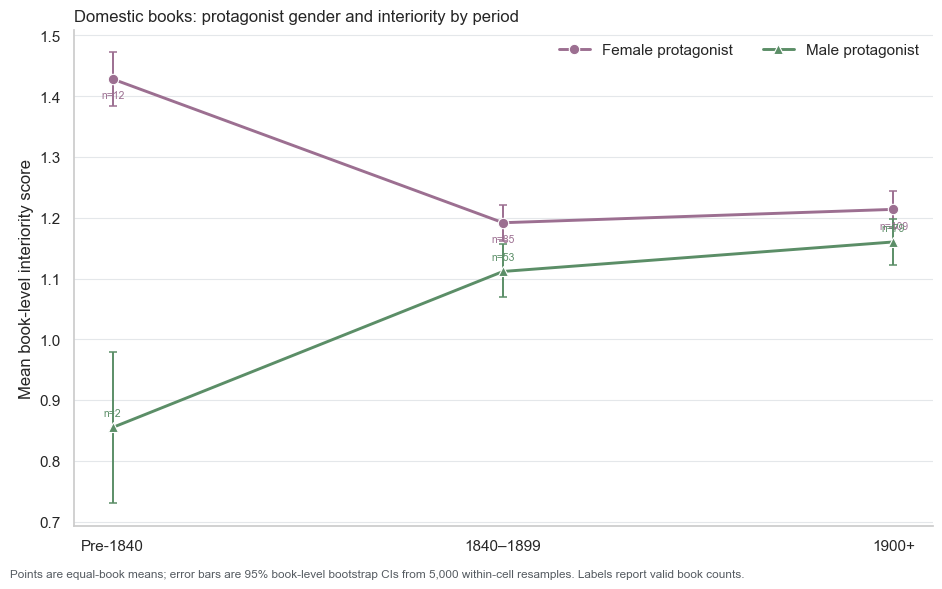

**Non-domestic books**

,protagonist_gender,time_period,historical_period,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,F,<1840,Pre-1840,18,1.373,1.317,1.432,limited_n_10_19,True,5000,20260731
1,F,1840-1899,1840–1899,69,1.093,1.049,1.140,standard_n_ge_20,True,5000,20260731
2,F,1900+,1900+,53,1.044,0.999,1.086,standard_n_ge_20,True,5000,20260731
3,M,<1840,Pre-1840,41,1.047,0.961,1.131,standard_n_ge_20,True,5000,20260731
4,M,1840-1899,1840–1899,166,0.946,0.915,0.978,standard_n_ge_20,True,5000,20260731
5,M,1900+,1900+,210,0.960,0.937,0.984,standard_n_ge_20,True,5000,20260731


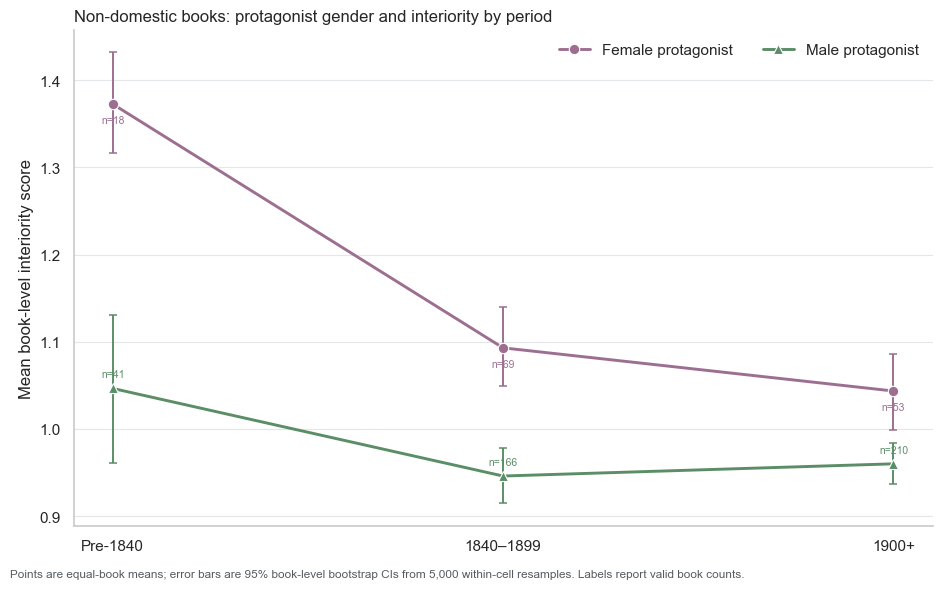

**Brief note.** Mixed protagonist books are excluded from these two F–M comparisons. Each point is an equal-book mean within a protagonist-gender × period cell; whiskers are 95% book-level bootstrap CIs.

In [19]:
PROTAGONIST_BINARY_ORDER = ["F", "M"]
PROTAGONIST_BINARY_LABELS = {
    "F": "Female protagonist",
    "M": "Male protagonist",
}
NON_DOMESTIC_BROAD_GROUPS = [
    "major_genre_non_domestic",
    "other_non_domestic_non_major_genre",
]

protagonist_binary_included = protagonist_included_books.loc[
    protagonist_included_books["protagonist_gender"].isin(
        PROTAGONIST_BINARY_ORDER
    )
].copy()

domestic_protagonist_gender_period_summary = summarize_gender_periods(
    protagonist_binary_included.loc[
        protagonist_binary_included["broad_group_analysis"].eq(
            "all_domestic"
        )
    ],
    group_column="protagonist_gender",
    groups=PROTAGONIST_BINARY_ORDER,
    seed_key="domestic_protagonist_gender_period",
)
domestic_protagonist_gender_period_summary.to_csv(
    author_table_dir / "protagonist_gender_domestic_period_bootstrap.csv",
    index=False,
)
display(
    Markdown("**Domestic books**")
)
display(
    domestic_protagonist_gender_period_summary.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)
fig = plot_gender_periods(
    domestic_protagonist_gender_period_summary,
    group_column="protagonist_gender",
    groups=PROTAGONIST_BINARY_ORDER,
    colors=PROTAGONIST_GENDER_COLORS,
    markers=PROTAGONIST_GENDER_MARKERS,
    labels=PROTAGONIST_BINARY_LABELS,
    title="Domestic books: protagonist gender and interiority by period",
    figure_stem="protagonist_gender_domestic_period_estimates",
)
plt.show()

non_domestic_protagonist_gender_period_summary = summarize_gender_periods(
    protagonist_binary_included.loc[
        protagonist_binary_included["broad_group_analysis"].isin(
            NON_DOMESTIC_BROAD_GROUPS
        )
    ],
    group_column="protagonist_gender",
    groups=PROTAGONIST_BINARY_ORDER,
    seed_key="non_domestic_protagonist_gender_period",
)
non_domestic_protagonist_gender_period_summary.to_csv(
    author_table_dir
    / "protagonist_gender_non_domestic_period_bootstrap.csv",
    index=False,
)
display(
    Markdown("**Non-domestic books**")
)
display(
    non_domestic_protagonist_gender_period_summary.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)
fig = plot_gender_periods(
    non_domestic_protagonist_gender_period_summary,
    group_column="protagonist_gender",
    groups=PROTAGONIST_BINARY_ORDER,
    colors=PROTAGONIST_GENDER_COLORS,
    markers=PROTAGONIST_GENDER_MARKERS,
    labels=PROTAGONIST_BINARY_LABELS,
    title="Non-domestic books: protagonist gender and interiority by period",
    figure_stem="protagonist_gender_non_domestic_period_estimates",
)
plt.show()

display(
    Markdown(
        "**Brief note.** Mixed protagonist books are excluded from these two F–M comparisons. "
        "Each point is an equal-book mean within a protagonist-gender × period cell; whiskers "
        "are 95% book-level bootstrap CIs."
    )
)


## 5. Gender overlap with broad-group analysis

All summaries use one observation per book and the mutually exclusive three-category `broad_group_analysis`.


### 5.1 Gender composition by broad group


,broad_group_analysis,gender_group,n_books,group_total,percent_within_broad_group,gender_type,broad_group_label,gender_label
0,all_domestic,female,208,463,44.9%,author_gender,All domestic,Female
1,all_domestic,male,255,463,55.1%,author_gender,All domestic,Male
2,major_genre_non_domestic,female,125,679,18.4%,author_gender,Non-domestic major genre,Female
3,major_genre_non_domestic,male,554,679,81.6%,author_gender,Non-domestic major genre,Male
4,other_non_domestic_non_major_genre,female,64,199,32.2%,author_gender,Other non-domestic,Female
5,other_non_domestic_non_major_genre,male,135,199,67.8%,author_gender,Other non-domestic,Male
6,all_domestic,F,236,454,52.0%,protagonist_gender,All domestic,F
7,all_domestic,M,165,454,36.3%,protagonist_gender,All domestic,M
8,all_domestic,mixed,53,454,11.7%,protagonist_gender,All domestic,Mixed
9,major_genre_non_domestic,F,135,662,20.4%,protagonist_gender,Non-domestic major genre,F


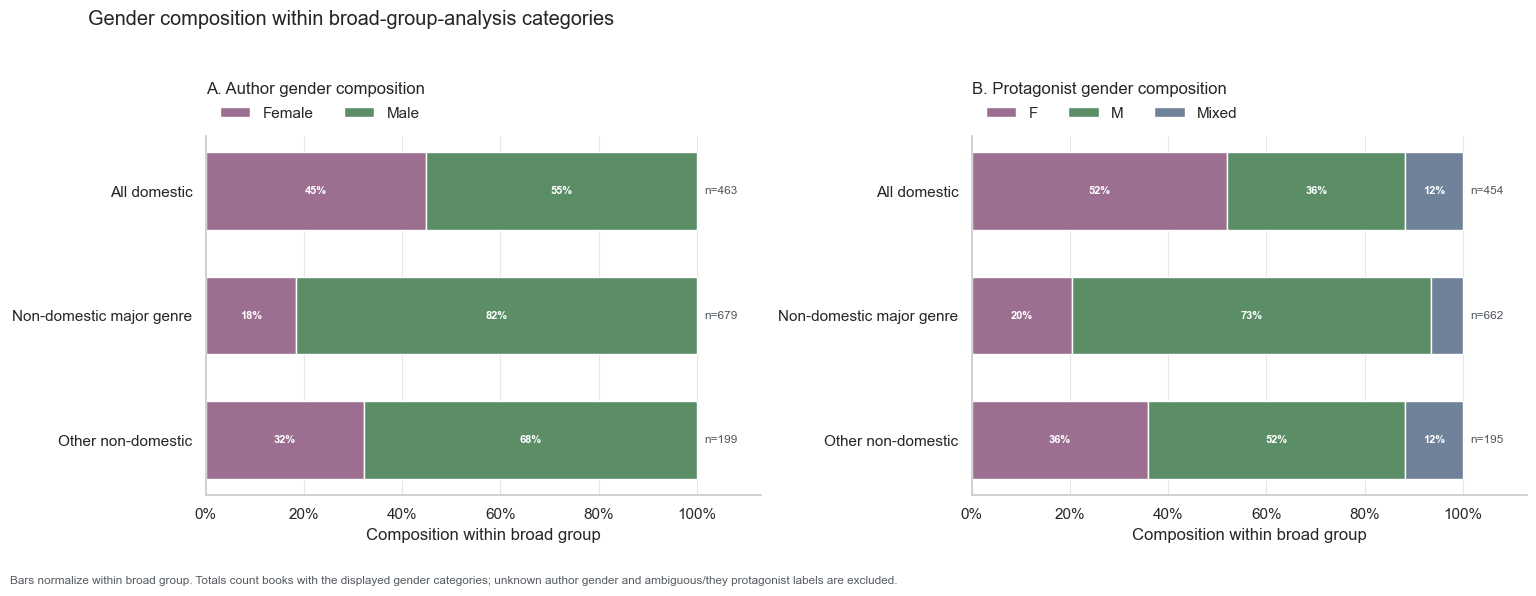

**Brief interpretation.** The panels describe how the valid gender categories are distributed within each mutually exclusive corpus group. Mixed remains a separate protagonist structure.

In [40]:
SECTION5_BROAD_GROUP_ORDER = [
    "all_domestic",
    "major_genre_non_domestic",
    "other_non_domestic_non_major_genre",
]
SECTION5_BROAD_GROUP_LABELS = {
    "all_domestic": "All domestic",
    "major_genre_non_domestic": "Non-domestic major genre",
    "other_non_domestic_non_major_genre": "Other non-domestic",
}
SECTION5_GENDER_COLORS = {
    "female": AUTHOR_GENDER_COLORS["female"],
    "male": AUTHOR_GENDER_COLORS["male"],
    "F": PROTAGONIST_GENDER_COLORS["F"],
    "M": PROTAGONIST_GENDER_COLORS["M"],
    "mixed": PROTAGONIST_GENDER_COLORS["mixed"],
}
SECTION5_GENDER_LABELS = {
    "female": "Female",
    "male": "Male",
    "F": "F",
    "M": "M",
    "mixed": "Mixed",
}


def build_gender_composition(
    data,
    *,
    gender_column,
    gender_groups,
    gender_type,
):
    working = (
        data.loc[
            data[gender_column].isin(gender_groups)
            & data["broad_group_analysis"].isin(
                SECTION5_BROAD_GROUP_ORDER
            ),
            ["gutenberg_id", gender_column, "broad_group_analysis"],
        ]
        .drop_duplicates("gutenberg_id")
        .copy()
    )
    full_index = pd.MultiIndex.from_product(
        [SECTION5_BROAD_GROUP_ORDER, gender_groups],
        names=["broad_group_analysis", "gender_group"],
    )
    composition = (
        working.groupby(
            ["broad_group_analysis", gender_column],
            observed=True,
        )
        .size()
        .rename("n_books")
    )
    composition.index = composition.index.set_names(
        ["broad_group_analysis", "gender_group"]
    )
    composition = composition.reindex(full_index, fill_value=0).reset_index()
    composition["group_total"] = composition.groupby(
        "broad_group_analysis"
    )["n_books"].transform("sum")
    composition["percent_within_broad_group"] = (
        composition["n_books"] / composition["group_total"]
    )
    composition["gender_type"] = gender_type
    composition["broad_group_label"] = composition[
        "broad_group_analysis"
    ].map(SECTION5_BROAD_GROUP_LABELS)
    composition["gender_label"] = composition["gender_group"].map(
        SECTION5_GENDER_LABELS
    )
    return composition


author_gender_composition = build_gender_composition(
    book_summary_analysis,
    gender_column="author_gender",
    gender_groups=AUTHOR_GENDER_ORDER,
    gender_type="author_gender",
)
protagonist_gender_composition = build_gender_composition(
    book_summary_analysis,
    gender_column="protagonist_gender",
    gender_groups=PROTAGONIST_GENDER_ORDER,
    gender_type="protagonist_gender",
)
gender_broad_group_composition = pd.concat(
    [author_gender_composition, protagonist_gender_composition],
    ignore_index=True,
)
gender_broad_group_composition.to_csv(
    author_table_dir / "section5_gender_composition_by_broad_group.csv",
    index=False,
)
display(
    gender_broad_group_composition.style.format(
        {"percent_within_broad_group": "{:.1%}"}
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), sharey=True)
panel_configs = [
    (
        axes[0],
        author_gender_composition,
        AUTHOR_GENDER_ORDER,
        "A. Author gender composition",
    ),
    (
        axes[1],
        protagonist_gender_composition,
        PROTAGONIST_GENDER_ORDER,
        "B. Protagonist gender composition",
    ),
]
y_positions = np.arange(len(SECTION5_BROAD_GROUP_ORDER))

for panel_index, (ax, panel_data, gender_groups, title) in enumerate(
    panel_configs
):
    left = np.zeros(len(SECTION5_BROAD_GROUP_ORDER))
    for gender_group in gender_groups:
        segment = (
            panel_data.loc[panel_data["gender_group"].eq(gender_group)]
            .set_index("broad_group_analysis")
            .reindex(SECTION5_BROAD_GROUP_ORDER)
        )
        percentages = segment["percent_within_broad_group"].to_numpy(float)
        bars = ax.barh(
            y_positions,
            percentages,
            left=left,
            color=SECTION5_GENDER_COLORS[gender_group],
            label=SECTION5_GENDER_LABELS[gender_group],
            height=0.62,
        )
        for y_position, percentage, segment_left in zip(
            y_positions,
            percentages,
            left,
        ):
            if percentage >= 0.08:
                ax.text(
                    segment_left + percentage / 2,
                    y_position,
                    f"{percentage:.0%}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white",
                    fontweight="bold",
                )
        left = left + percentages

    totals = (
        panel_data.groupby("broad_group_analysis", observed=True)[
            "n_books"
        ]
        .sum()
        .reindex(SECTION5_BROAD_GROUP_ORDER)
    )
    for y_position, total in zip(y_positions, totals):
        ax.text(
            1.015,
            y_position,
            f"n={int(total)}",
            va="center",
            fontsize=8.5,
            color="#4F555B",
        )
    ax.set_title(title, loc="left", pad=30)
    ax.set_xlim(0, 1.13)
    ax.set_xlabel("Composition within broad group")
    ax.set_yticks(
        y_positions,
        [
            SECTION5_BROAD_GROUP_LABELS[group]
            for group in SECTION5_BROAD_GROUP_ORDER
        ],
    )
    ax.tick_params(axis="y", labelleft=True)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(
        frameon=False,
        loc="lower left",
        bbox_to_anchor=(0, 1.005),
        ncol=len(gender_groups),
    )
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    sns.despine(ax=ax)

axes[0].invert_yaxis()
fig.suptitle("Gender composition within broad-group-analysis categories", x=0.06, ha="left")
fig.text(
    0.01,
    -0.01,
    "Bars normalize within broad group. Totals count books with the displayed gender categories; "
    "unknown author gender and ambiguous/they protagonist labels are excluded.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
save_figure(
    fig,
    author_figure_dir,
    "section5_gender_composition_by_broad_group",
)
plt.show()
display(
    Markdown(
        "**Brief interpretation.** The panels describe how the valid gender categories are distributed "
        "within each mutually exclusive corpus group. Mixed remains a separate protagonist structure."
    )
)


### 5.2 Interiority by gender × broad group


,gender_type,gender_group,gender_label,broad_group_analysis,broad_group_label,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,author_gender,female,Female,all_domestic,All domestic,208,1.217,1.195,1.238,standard_n_ge_20,True,5000,20260731
1,author_gender,male,Male,all_domestic,All domestic,255,1.170,1.148,1.191,standard_n_ge_20,True,5000,20260731
2,author_gender,female,Female,major_genre_non_domestic,Non-domestic major genre,125,1.068,1.032,1.106,standard_n_ge_20,True,5000,20260731
3,author_gender,male,Male,major_genre_non_domestic,Non-domestic major genre,554,0.965,0.948,0.982,standard_n_ge_20,True,5000,20260731
4,author_gender,female,Female,other_non_domestic_non_major_genre,Other non-domestic,64,1.221,1.169,1.274,standard_n_ge_20,True,5000,20260731
5,author_gender,male,Male,other_non_domestic_non_major_genre,Other non-domestic,135,1.090,1.056,1.124,standard_n_ge_20,True,5000,20260731
6,protagonist_gender,F,F,all_domestic,All domestic,236,1.218,1.198,1.238,standard_n_ge_20,True,5000,20260731
7,protagonist_gender,M,M,all_domestic,All domestic,165,1.150,1.123,1.176,standard_n_ge_20,True,5000,20260731
8,protagonist_gender,mixed,Mixed,all_domestic,All domestic,53,1.203,1.159,1.245,standard_n_ge_20,True,5000,20260731
9,protagonist_gender,F,F,major_genre_non_domestic,Non-domestic major genre,135,1.092,1.059,1.125,standard_n_ge_20,True,5000,20260731


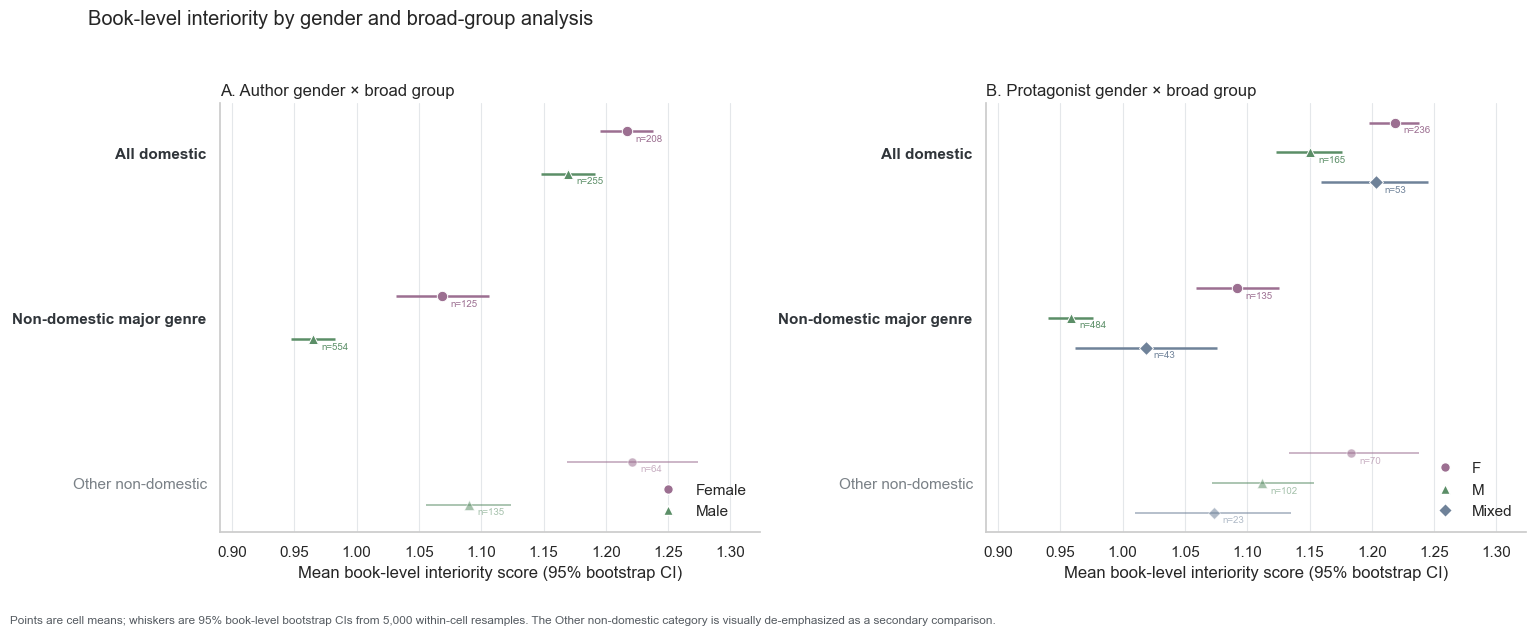

**Brief interpretation.** These are descriptive cell means with one vote per book. Mixed protagonist books are retained as a distinct structural category rather than placed between F and M.

In [41]:
def summarize_gender_broad_group_cells(
    data,
    *,
    gender_column,
    gender_groups,
    gender_type,
):
    rows = []
    for broad_group in SECTION5_BROAD_GROUP_ORDER:
        for gender_group in gender_groups:
            values = data.loc[
                data["broad_group_analysis"].eq(broad_group)
                & data[gender_column].eq(gender_group),
                "avg_interiority_score",
            ]
            summary = bootstrap_mean_summary(
                values,
                "section5_gender_broad_group_cell",
                gender_type,
                broad_group,
                gender_group,
            )
            rows.append(
                {
                    "gender_type": gender_type,
                    "gender_group": gender_group,
                    "gender_label": SECTION5_GENDER_LABELS[gender_group],
                    "broad_group_analysis": broad_group,
                    "broad_group_label": SECTION5_BROAD_GROUP_LABELS[
                        broad_group
                    ],
                    **summary,
                }
            )
    return pd.DataFrame(rows)


author_gender_broad_group_interiority = summarize_gender_broad_group_cells(
    book_summary_analysis,
    gender_column="author_gender",
    gender_groups=AUTHOR_GENDER_ORDER,
    gender_type="author_gender",
)
protagonist_gender_broad_group_interiority = (
    summarize_gender_broad_group_cells(
        book_summary_analysis,
        gender_column="protagonist_gender",
        gender_groups=PROTAGONIST_GENDER_ORDER,
        gender_type="protagonist_gender",
    )
)
gender_broad_group_interiority = pd.concat(
    [
        author_gender_broad_group_interiority,
        protagonist_gender_broad_group_interiority,
    ],
    ignore_index=True,
)
gender_broad_group_interiority.to_csv(
    author_table_dir
    / "section5_gender_broad_group_interiority_bootstrap.csv",
    index=False,
)
display(
    gender_broad_group_interiority.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2), sharex=True, sharey=True)
panel_configs = [
    (
        axes[0],
        author_gender_broad_group_interiority,
        AUTHOR_GENDER_ORDER,
        {"female": -0.13, "male": 0.13},
        GENDER_MARKERS,
        "A. Author gender × broad group",
    ),
    (
        axes[1],
        protagonist_gender_broad_group_interiority,
        PROTAGONIST_GENDER_ORDER,
        {"F": -0.18, "M": 0.0, "mixed": 0.18},
        PROTAGONIST_GENDER_MARKERS,
        "B. Protagonist gender × broad group",
    ),
]
y_positions = np.arange(len(SECTION5_BROAD_GROUP_ORDER))

for panel_index, (
    ax,
    panel_data,
    gender_groups,
    gender_offsets,
    markers,
    title,
) in enumerate(panel_configs):
    for broad_index, broad_group in enumerate(SECTION5_BROAD_GROUP_ORDER):
        secondary = broad_group == "other_non_domestic_non_major_genre"
        for gender_group in gender_groups:
            row = panel_data.loc[
                panel_data["broad_group_analysis"].eq(broad_group)
                & panel_data["gender_group"].eq(gender_group)
            ].iloc[0]
            y_value = broad_index + gender_offsets[gender_group]
            color = SECTION5_GENDER_COLORS[gender_group]
            alpha = 0.55 if secondary else 1.0
            ax.hlines(
                y_value,
                row["ci_low"],
                row["ci_high"],
                color=color,
                linewidth=1.3 if secondary else 1.8,
                alpha=alpha,
                zorder=2,
            )
            ax.plot(
                row["estimate"],
                y_value,
                marker=markers[gender_group],
                markersize=6.5 if secondary else 7.5,
                markerfacecolor=color,
                markeredgecolor="white",
                markeredgewidth=0.7,
                alpha=alpha,
                linestyle="none",
                zorder=3,
            )
            ax.annotate(
                f"n={int(row['n_books'])}",
                (row["estimate"], y_value),
                xytext=(6, -7),
                textcoords="offset points",
                fontsize=7,
                color=color,
                alpha=alpha,
            )

    legend_handles = [
        plt.Line2D(
            [0],
            [0],
            marker=markers[gender_group],
            linestyle="none",
            markerfacecolor=SECTION5_GENDER_COLORS[gender_group],
            markeredgecolor="white",
            markersize=7,
            label=SECTION5_GENDER_LABELS[gender_group],
        )
        for gender_group in gender_groups
    ]
    ax.legend(handles=legend_handles, frameon=False, loc="lower right")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Mean book-level interiority score (95% bootstrap CI)")
    ax.set_yticks(
        y_positions,
        [
            SECTION5_BROAD_GROUP_LABELS[group]
            for group in SECTION5_BROAD_GROUP_ORDER
        ],
    )
    ax.tick_params(axis="y", labelleft=True)
    for tick_index, tick_label in enumerate(ax.get_yticklabels()):
        tick_label.set_fontweight("bold" if tick_index < 2 else "normal")
        tick_label.set_color("#30353A" if tick_index < 2 else "#7A8187")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    ax.margins(x=0.15)
    sns.despine(ax=ax)

axes[0].invert_yaxis()
fig.suptitle("Book-level interiority by gender and broad-group analysis", x=0.06, ha="left")
fig.text(
    0.01,
    -0.01,
    "Points are cell means; whiskers are 95% book-level bootstrap CIs from 5,000 within-cell resamples. "
    "The Other non-domestic category is visually de-emphasized as a secondary comparison.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
save_figure(
    fig,
    author_figure_dir,
    "section5_gender_broad_group_interiority",
)
plt.show()
display(
    Markdown(
        "**Brief interpretation.** These are descriptive cell means with one vote per book. "
        "Mixed protagonist books are retained as a distinct structural category rather than placed between F and M."
    )
)


### 5.3 Gender-gap interaction summary


,gender_type,difference_label,broad_group_analysis,broad_group_label,group_a,group_b,n_group_a,n_group_b,group_a_mean,group_b_mean,difference,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,author_gender,Female author − Male author,all_domestic,All domestic,female,male,208,255,1.217,1.170,+0.048,+0.016,+0.078,standard_n_ge_20,True,5000,20260731
1,author_gender,Female author − Male author,major_genre_non_domestic,Non-domestic major genre,female,male,125,554,1.068,0.965,+0.103,+0.063,+0.145,standard_n_ge_20,True,5000,20260731
2,author_gender,Female author − Male author,other_non_domestic_non_major_genre,Other non-domestic,female,male,64,135,1.221,1.090,+0.131,+0.070,+0.195,standard_n_ge_20,True,5000,20260731
3,protagonist_gender,F protagonist − M protagonist,all_domestic,All domestic,F,M,236,165,1.218,1.150,+0.068,+0.035,+0.104,standard_n_ge_20,True,5000,20260731
4,protagonist_gender,F protagonist − M protagonist,major_genre_non_domestic,Non-domestic major genre,F,M,135,484,1.092,0.959,+0.134,+0.096,+0.174,standard_n_ge_20,True,5000,20260731
5,protagonist_gender,F protagonist − M protagonist,other_non_domestic_non_major_genre,Other non-domestic,F,M,70,102,1.184,1.112,+0.072,+0.005,+0.137,standard_n_ge_20,True,5000,20260731


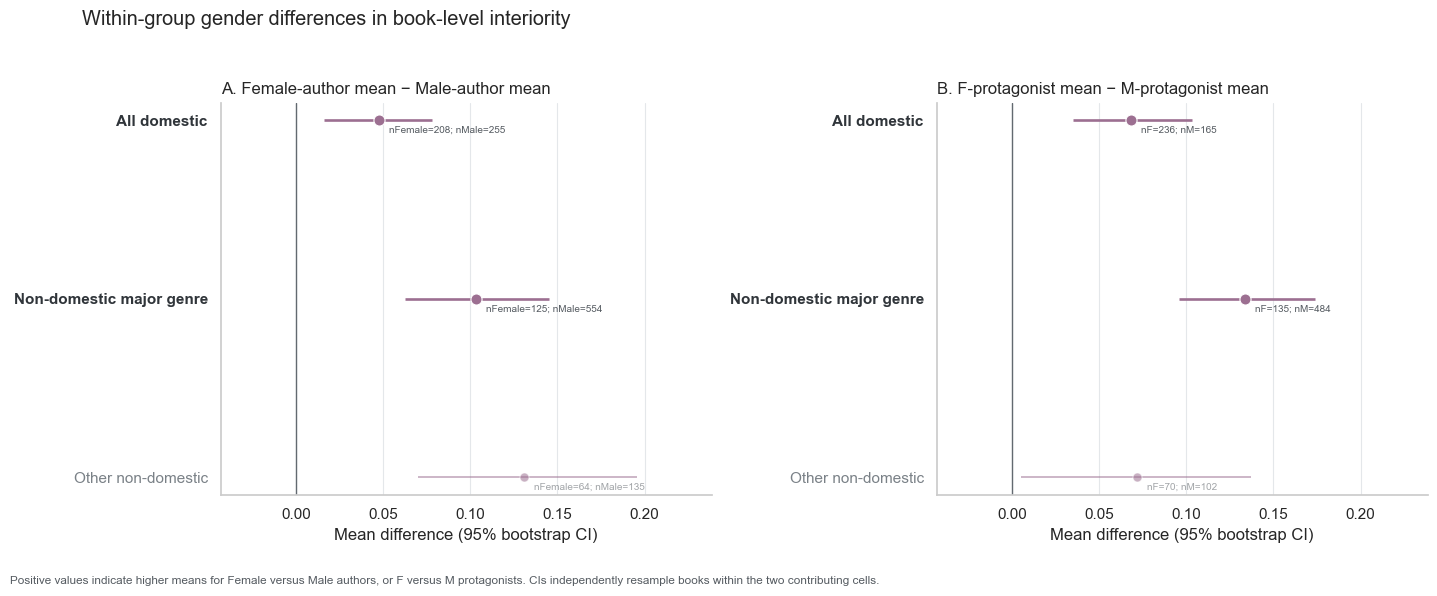

**Brief interpretation.** The differences are descriptive interactions within corpus groups. They should be read with both contributing sample sizes, particularly for smaller cells.

In [42]:
def summarize_gender_difference_by_broad_group(
    data,
    *,
    gender_column,
    group_a,
    group_b,
    gender_type,
    difference_label,
):
    rows = []
    for broad_group in SECTION5_BROAD_GROUP_ORDER:
        group_a_values = data.loc[
            data["broad_group_analysis"].eq(broad_group)
            & data[gender_column].eq(group_a),
            "avg_interiority_score",
        ]
        group_b_values = data.loc[
            data["broad_group_analysis"].eq(broad_group)
            & data[gender_column].eq(group_b),
            "avg_interiority_score",
        ]
        summary = bootstrap_difference_summary(
            group_a_values,
            group_b_values,
            "section5_gender_difference",
            gender_type,
            broad_group,
        )
        rows.append(
            {
                "gender_type": gender_type,
                "difference_label": difference_label,
                "broad_group_analysis": broad_group,
                "broad_group_label": SECTION5_BROAD_GROUP_LABELS[
                    broad_group
                ],
                "group_a": group_a,
                "group_b": group_b,
                "n_group_a": summary["n_genre"],
                "n_group_b": summary["n_domestic"],
                "group_a_mean": summary["genre_mean"],
                "group_b_mean": summary["domestic_mean"],
                "difference": summary["difference"],
                "ci_low": summary["ci_low"],
                "ci_high": summary["ci_high"],
                "sample_status": summary["sample_status"],
                "ci_displayed": summary["ci_displayed"],
                "bootstrap_repetitions": summary[
                    "bootstrap_repetitions"
                ],
                "bootstrap_seed": summary["bootstrap_seed"],
            }
        )
    return pd.DataFrame(rows)


author_gender_difference = summarize_gender_difference_by_broad_group(
    book_summary_analysis,
    gender_column="author_gender",
    group_a="female",
    group_b="male",
    gender_type="author_gender",
    difference_label="Female author − Male author",
)
protagonist_gender_difference = summarize_gender_difference_by_broad_group(
    book_summary_analysis,
    gender_column="protagonist_gender",
    group_a="F",
    group_b="M",
    gender_type="protagonist_gender",
    difference_label="F protagonist − M protagonist",
)
gender_broad_group_differences = pd.concat(
    [author_gender_difference, protagonist_gender_difference],
    ignore_index=True,
)
gender_broad_group_differences.to_csv(
    author_table_dir
    / "section5_gender_difference_by_broad_group_bootstrap.csv",
    index=False,
)
display(
    gender_broad_group_differences.style.format(
        {
            "group_a_mean": "{:.3f}",
            "group_b_mean": "{:.3f}",
            "difference": "{:+.3f}",
            "ci_low": "{:+.3f}",
            "ci_high": "{:+.3f}",
        }
    )
)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharex=True, sharey=True)
panel_configs = [
    (
        axes[0],
        author_gender_difference,
        "A. Female-author mean − Male-author mean",
        AUTHOR_GENDER_COLORS["female"],
        "Female",
        "Male",
    ),
    (
        axes[1],
        protagonist_gender_difference,
        "B. F-protagonist mean − M-protagonist mean",
        PROTAGONIST_GENDER_COLORS["F"],
        "F",
        "M",
    ),
]
y_positions = np.arange(len(SECTION5_BROAD_GROUP_ORDER))

for panel_index, (
    ax,
    panel_data,
    title,
    color,
    group_a_label,
    group_b_label,
) in enumerate(panel_configs):
    panel = (
        panel_data.set_index("broad_group_analysis")
        .reindex(SECTION5_BROAD_GROUP_ORDER)
    )
    ax.axvline(0, color="#626970", linewidth=1.0, zorder=1)
    for y_position, (broad_group, row) in zip(
        y_positions,
        panel.iterrows(),
    ):
        secondary = broad_group == "other_non_domestic_non_major_genre"
        alpha = 0.55 if secondary else 1.0
        ax.hlines(
            y_position,
            row["ci_low"],
            row["ci_high"],
            color=color,
            linewidth=1.3 if secondary else 1.9,
            alpha=alpha,
            zorder=2,
        )
        ax.plot(
            row["difference"],
            y_position,
            marker="o",
            markersize=6.5 if secondary else 8,
            markerfacecolor=color,
            markeredgecolor="white",
            markeredgewidth=0.8,
            alpha=alpha,
            linestyle="none",
            zorder=3,
        )
        ax.annotate(
            f"n{group_a_label}={int(row['n_group_a'])}; "
            f"n{group_b_label}={int(row['n_group_b'])}",
            (row["difference"], y_position),
            xytext=(7, -9),
            textcoords="offset points",
            fontsize=7.2,
            color="#555B61",
            alpha=alpha,
        )

    ax.set_title(title, loc="left")
    ax.set_xlabel("Mean difference (95% bootstrap CI)")
    ax.set_yticks(
        y_positions,
        [
            SECTION5_BROAD_GROUP_LABELS[group]
            for group in SECTION5_BROAD_GROUP_ORDER
        ],
    )
    ax.tick_params(axis="y", labelleft=True)
    for tick_index, tick_label in enumerate(ax.get_yticklabels()):
        tick_label.set_fontweight("bold" if tick_index < 2 else "normal")
        tick_label.set_color("#30353A" if tick_index < 2 else "#7A8187")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    ax.margins(x=0.22)
    sns.despine(ax=ax)

axes[0].invert_yaxis()
fig.suptitle("Within-group gender differences in book-level interiority", x=0.06, ha="left")
fig.text(
    0.01,
    -0.01,
    "Positive values indicate higher means for Female versus Male authors, or F versus M protagonists. "
    "CIs independently resample books within the two contributing cells.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
save_figure(
    fig,
    author_figure_dir,
    "section5_gender_difference_by_broad_group",
)
plt.show()
display(
    Markdown(
        "**Brief interpretation.** The differences are descriptive interactions within corpus groups. "
        "They should be read with both contributing sample sizes, particularly for smaller cells."
    )
)


## 6. Author gender × protagonist gender

The main exploratory interaction uses female/male authors and F/M protagonists. Books with mixed protagonists are excluded from the 2×2 comparison and summarized separately. All analyses in this section are restricted to books with `protagonist_analysis_status == "included"`, and all estimates give equal weight to each book.


### 6.1 Main 2×2 interaction


,author_gender_label,protagonist_gender,n_books,estimate,ci_low,ci_high
0,Female author,F,205,1.207,1.183,1.231
1,Female author,M,89,1.111,1.064,1.157
2,Male author,F,138,1.128,1.096,1.161
3,Male author,M,459,0.985,0.966,1.003


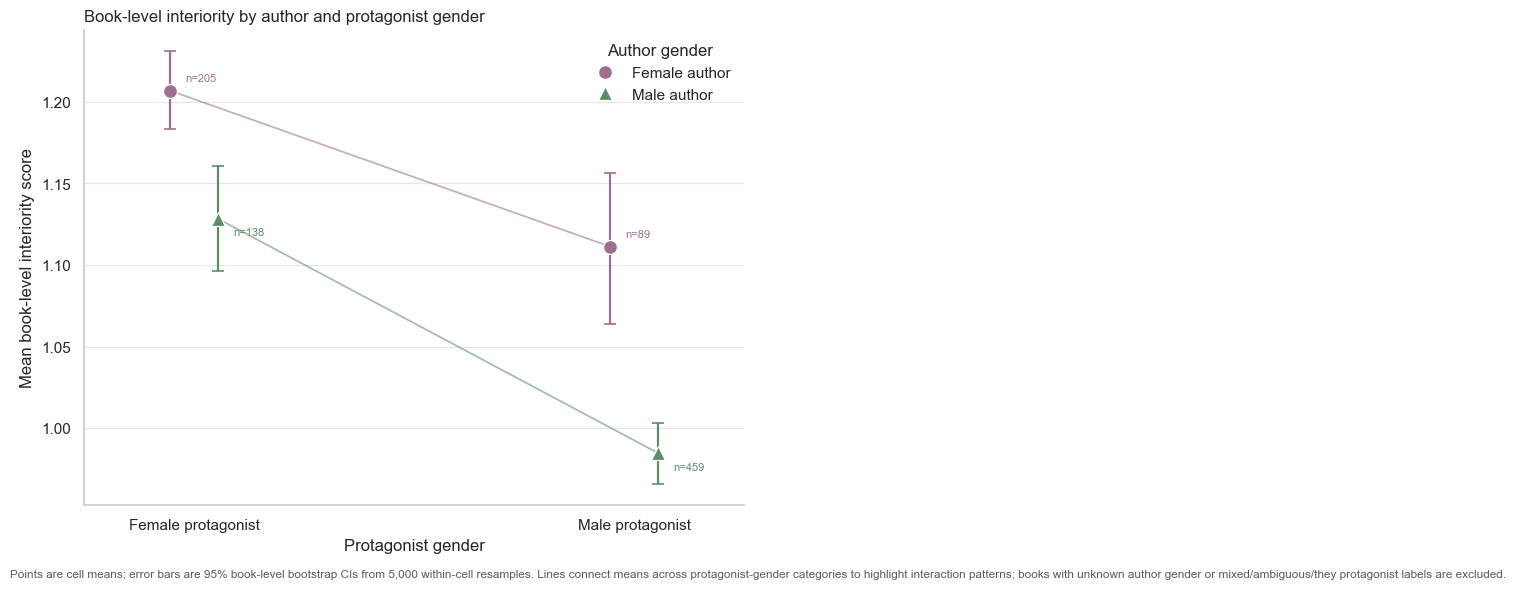

**Brief interpretation.** F-protagonist books have higher descriptive cell means than M-protagonist books within both author-gender groups. The within-author differences are +0.096 for female authors and +0.144 for male authors; these are exploratory comparisons, not adjusted interaction estimates.

In [23]:
section6_included_books = (
    book_summary_analysis.loc[
        book_summary_analysis["protagonist_analysis_status"].eq("included")
    ]
    .copy()
)

INTERACTION_AUTHOR_ORDER = ["female", "male"]
INTERACTION_PROTAGONIST_ORDER = ["F", "M"]
INTERACTION_AUTHOR_LABELS = {
    "female": "Female author",
    "male": "Male author",
}

author_protagonist_interaction_rows = []
for author_group in INTERACTION_AUTHOR_ORDER:
    for protagonist_group in INTERACTION_PROTAGONIST_ORDER:
        values = section6_included_books.loc[
            section6_included_books["author_gender"].eq(author_group)
            & section6_included_books["protagonist_gender"].eq(
                protagonist_group
            ),
            "avg_interiority_score",
        ]
        summary = bootstrap_mean_summary(
            values,
            "section6_author_protagonist_interaction",
            author_group,
            protagonist_group,
        )
        author_protagonist_interaction_rows.append(
            {
                "author_gender": author_group,
                "author_gender_label": INTERACTION_AUTHOR_LABELS[
                    author_group
                ],
                "protagonist_gender": protagonist_group,
                **summary,
            }
        )

author_protagonist_interaction_summary = pd.DataFrame(
    author_protagonist_interaction_rows
)
author_protagonist_interaction_summary.to_csv(
    author_table_dir
    / "section6_author_protagonist_gender_2x2_bootstrap.csv",
    index=False,
)
display(
    author_protagonist_interaction_summary[
        [
            "author_gender_label",
            "protagonist_gender",
            "n_books",
            "estimate",
            "ci_low",
            "ci_high",
        ]
    ].style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(7.6, 5.8))
base_x = np.array([0.0, 0.64])
author_x_offsets = {
    "female": -0.035,
    "male": 0.035,
}
count_offsets = {
    "female": (11, 7),
    "male": (11, -12),
}

for author_group in INTERACTION_AUTHOR_ORDER:
    panel = (
        author_protagonist_interaction_summary.loc[
            author_protagonist_interaction_summary["author_gender"].eq(
                author_group
            )
        ]
        .set_index("protagonist_gender")
        .reindex(INTERACTION_PROTAGONIST_ORDER)
    )
    x_values = base_x + author_x_offsets[author_group]
    estimates = panel["estimate"].to_numpy(float)
    ci_low = panel["ci_low"].to_numpy(float)
    ci_high = panel["ci_high"].to_numpy(float)
    color = AUTHOR_GENDER_COLORS[author_group]
    marker = GENDER_MARKERS[author_group]

    ax.plot(
        x_values,
        estimates,
        color=color,
        linewidth=1.25,
        alpha=0.58,
        zorder=2,
    )
    ax.errorbar(
        x_values,
        estimates,
        yerr=np.vstack(
            [
                estimates - ci_low,
                ci_high - estimates,
            ]
        ),
        fmt="none",
        ecolor=color,
        elinewidth=1.6,
        capsize=4.5,
        capthick=1.2,
        zorder=3,
    )
    ax.plot(
        x_values,
        estimates,
        color=color,
        marker=marker,
        markersize=10,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=0.9,
        linestyle="none",
        label=INTERACTION_AUTHOR_LABELS[author_group],
        zorder=4,
    )
    for x_value, estimate, n_books in zip(
        x_values,
        estimates,
        panel["n_books"].to_numpy(int),
    ):
        ax.annotate(
            f"n={n_books}",
            (x_value, estimate),
            xytext=count_offsets[author_group],
            textcoords="offset points",
            ha="left",
            fontsize=8,
            color=color,
        )

ax.set_xticks(
    base_x,
    ["Female protagonist", "Male protagonist"],
)
ax.set_xlim(-0.16, 0.80)
ax.set_xlabel("Protagonist gender")
ax.set_ylabel("Mean book-level interiority score")
ax.set_title(
    "Book-level interiority by author and protagonist gender",
    loc="left",
)
ax.legend(title="Author gender", frameon=False, loc="best")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
fig.text(
    0.01,
    -0.01,
    "Points are cell means; error bars are 95% book-level bootstrap CIs from "
    "5,000 within-cell resamples. Lines connect means across protagonist-gender categories to highlight interaction patterns; "
    "books with unknown author gender or mixed/ambiguous/they protagonist labels are excluded.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(
    fig,
    author_figure_dir,
    "section6_author_protagonist_gender_interaction",
)
plt.show()

interaction_pivot = author_protagonist_interaction_summary.pivot(
    index="author_gender",
    columns="protagonist_gender",
    values="estimate",
)
female_author_f_minus_m = (
    interaction_pivot.loc["female", "F"]
    - interaction_pivot.loc["female", "M"]
)
male_author_f_minus_m = (
    interaction_pivot.loc["male", "F"]
    - interaction_pivot.loc["male", "M"]
)
display(
    Markdown(
        f"**Brief interpretation.** F-protagonist books have higher descriptive cell means than "
        f"M-protagonist books within both author-gender groups. The within-author differences are "
        f"{female_author_f_minus_m:+.3f} for female authors and {male_author_f_minus_m:+.3f} for male authors; "
        "these are exploratory comparisons, not adjusted interaction estimates."
    )
)


### 6.2 Supplementary mixed-protagonist summary


In [24]:
mixed_protagonist_rows = []
for author_group in INTERACTION_AUTHOR_ORDER:
    values = section6_included_books.loc[
        section6_included_books["author_gender"].eq(author_group)
        & section6_included_books["protagonist_gender"].eq("mixed"),
        "avg_interiority_score",
    ]
    summary = bootstrap_mean_summary(
        values,
        "section6_mixed_protagonist_by_author_gender",
        author_group,
    )
    mixed_protagonist_rows.append(
        {
            "author_gender": author_group,
            "author_gender_label": INTERACTION_AUTHOR_LABELS[
                author_group
            ],
            "protagonist_gender": "mixed",
            **summary,
        }
    )

mixed_protagonist_by_author_gender = pd.DataFrame(
    mixed_protagonist_rows
)
mixed_protagonist_by_author_gender.to_csv(
    author_table_dir
    / "section6_mixed_protagonist_by_author_gender_bootstrap.csv",
    index=False,
)
display(
    mixed_protagonist_by_author_gender[
        [
            "author_gender_label",
            "protagonist_gender",
            "n_books",
            "estimate",
            "ci_low",
            "ci_high",
        ]
    ].style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)
display(
    Markdown(
        "**Brief interpretation.** Mixed is retained as a separate structural category and is not "
        "positioned between F and M in the main interaction."
    )
)


,author_gender_label,protagonist_gender,n_books,estimate,ci_low,ci_high
0,Female author,mixed,45,1.124,1.075,1.172
1,Male author,mixed,74,1.104,1.059,1.149


**Brief interpretation.** Mixed is retained as a separate structural category and is not positioned between F and M in the main interaction.